# Part 3 of 4: Optimization experiments
**Project:** How High Will Gas Prices Get Tomorrow? · **Team:** Orville Rockwell Jr., Yi-Ting Lin, Wejun Chen, Yixin Tian

**Owner:** Yi-Ting Lin

Two controlled experiments (dropout, learning rate) on the weekly GARCH-LSTM-t, then the combined setting.

**Your task:** improve this part in 5 specific ways. Put each in a Markdown cell titled **Revision** (what you changed, why, and the result), and keep a log of what you did and when for the contribution table.

## Setup (run this cell first, every time)
It installs any missing packages, then writes the project code (`gaslab/`) and the real data (`data/`) into this
notebook's folder **only if they are not there yet**. If you edit a file in `gaslab/` or drop newer CSVs in `data/`,
re-running this cell will not overwrite them. Data: EIA/FRED weekly retail and daily wholesale and crude prices
from Jan 2014 to Oct 2026, plus every settled Kalshi AAA gas contract (the daily AAA labels).

In [1]:
import sys, os, base64, shutil, subprocess, importlib.util
need = [pkg for pkg, mod in [("arch", "arch"), ("statsmodels", "statsmodels"), ("scikit-learn", "sklearn"),
                             ("tensorflow", "tensorflow"), ("matplotlib", "matplotlib"), ("scipy", "scipy")]
        if importlib.util.find_spec(mod) is None]
if need:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need]); print("installed:", need)
VERSION = '2026-11-08'
CODE = {'__init__.py': '', 'data.py': '"""Data layer: FRED wholesale/crude/retail + Kalshi AAA settlements -> leak-free feature tensors.\n\nTiming conventions (all decisions are made with information available at the bid time):\n  * Weekly model: origin = Monday t (EIA retail R_t surveyed 8 a.m. Monday). Target = log(R_{t+1}/R_t).\n    Wholesale/crude inputs use closes through the Friday before Monday t.\n  * Daily model: origin = 8:00 a.m. ET on day D-1, when Kalshi opens the contract settling on day D.\n    AAA\'s D-1 average is already posted (Kalshi centres the strike ladder on it). Wholesale/crude\n    inputs use closes through business day D-2. Target = log(A_D/A_{D-1}).\n"""\nfrom pathlib import Path\nimport numpy as np, pandas as pd\n\nDATA = Path(__file__).resolve().parent.parent / "data"\nGAL_PER_BBL = 42.0\n\n\ndef load_fred():\n    f = pd.read_csv(DATA / "fred.csv", parse_dates=["date"]).set_index("date").sort_index()\n    f["wti"] /= GAL_PER_BBL; f["brent"] /= GAL_PER_BBL            # $/bbl -> $/gal\n    f.loc[f["wti"] <= 0, "wti"] = np.nan                           # 2020-04-20 negative WTI print\n    return f\n\n\ndef load_aaa_daily():\n    """AAA national regular average by date, from Kalshi settlement values plus any manual rows."""\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series.isin(["KXAAAGASD", "KXAAAGASW", "KXAAAGASM"])].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["value"] = pd.to_numeric(k.value, errors="coerce")\n    s = k.dropna(subset=["value"]).groupby("date").value.first()\n    manual = DATA / "manual_aaa.csv"                               # optional: date,aaa\n    if manual.exists():\n        m = pd.read_csv(manual, parse_dates=["date"]).set_index("date")["aaa"]\n        s = pd.concat([s, m]).groupby(level=0).last()\n    return s.sort_index().rename("aaa")\n\n\ndef daily_contracts(series="KXAAAGASD"):\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series == series].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["y"] = (k.result == "yes").astype(float).where(k.result.isin(["yes", "no"]))\n    book = DATA / "kalshi_open_book.csv"\n    if book.exists():\n        k = k.merge(pd.read_csv(book)[["ticker", "bid", "ask", "hours_after_open"]], on="ticker", how="left")\n    return k\n\n\n# ----------------------------------------------------------------------------------- weekly (10 years)\nWEEKLY_FEATS = ["d_retail", "d_gulf", "d_nyh", "d_brent", "up_gulf", "dn_gulf", "ect", "garch_sd"]\n\n\ndef weekly_frame(f=None):\n    """One row per EIA Monday t with features known at t and target y = log(R_{t+1}/R_t)."""\n    f = load_fred() if f is None else f\n    r = f["retail_eia_weekly"].dropna()\n    bd = f[["whsl_gulf", "whsl_nyh", "brent"]].ffill()\n    rows = []\n    for t in r.index:\n        fri = bd.loc[: t - pd.Timedelta(days=3)].tail(5)            # Mon-Fri week ending the Friday before t\n        if len(fri) < 5: continue\n        rows.append(dict(date=t, retail=r.loc[t], gulf=fri.whsl_gulf.mean(), nyh=fri.whsl_nyh.mean(), brent=fri.brent.mean()))\n    w = pd.DataFrame(rows).set_index("date")\n    lw = np.log(w)\n    w["d_retail"] = lw.retail.diff(); w["d_gulf"] = lw.gulf.diff(); w["d_nyh"] = lw.nyh.diff(); w["d_brent"] = lw.brent.diff()\n    w["up_gulf"] = w.d_gulf.clip(lower=0); w["dn_gulf"] = w.d_gulf.clip(upper=0)         # rockets & feathers\n    spread = lw.retail - lw.gulf                                                          # retail margin (log)\n    w["ect"] = spread - spread.rolling(52, min_periods=26).mean()                        # error-correction term\n    w["y"] = w.d_retail.shift(-1)\n    return w\n\n\n# ----------------------------------------------------------------------------------- daily (Kalshi)\nDAILY_FEATS = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift", "garch_sd"]\n\n\ndef daily_frame(f=None, aaa=None, weekly_drift=None, extend_to=None):\n    """One row per settlement day D with features known at 8 a.m. ET on D-1.\n    extend_to adds future settlement dates (no target yet) so live contracts can be priced."""\n    f = load_fred() if f is None else f\n    aaa = load_aaa_daily() if aaa is None else aaa\n    a = aaa.asfreq("D")\n    if extend_to is not None and pd.Timestamp(extend_to) > a.index[-1]:\n        a = a.reindex(pd.date_range(a.index[0], extend_to, freq="D"))\n    bd = f[["whsl_gulf", "brent"]].ffill().asfreq("D").reindex(a.index.union(f.index)).ffill().reindex(a.index)\n    df = pd.DataFrame(index=a.index)\n    df["aaa_prev"] = a.shift(1)                                          # A_{D-1}\n    df["d_aaa"] = np.log(a).diff().shift(1)                              # change into D-1\n    df["d_aaa_l2"] = df["d_aaa"].shift(1)                                # change into D-2\n    g2 = np.log(bd.whsl_gulf).shift(2); b2 = np.log(bd.brent).shift(2)   # closes through D-2\n    df["d_gulf"] = g2.diff(); df["d_brent"] = b2.diff()\n    spread = np.log(df.aaa_prev) - g2.rolling(5).mean()\n    df["ect"] = spread - spread.rolling(28, min_periods=10).mean()\n    df["w_drift"] = 0.0 if weekly_drift is None else weekly_drift.reindex(df.index, method="ffill").fillna(0) / 7.0\n    df["y"] = np.log(a).diff()\n    return df\n\n\ndef sequences(df, feats, lookback, rows=None, allow_missing_y=()):\n    """Stack rolling windows of features ending at each row. Returns X, y, index.\n    Rows listed in allow_missing_y are kept even without a target (used for live forecasts)."""\n    vals = df[feats].values.astype("float32"); ys = df["y"].values.astype("float32")\n    idx = []; X = []; Y = []\n    want = set(df.index if rows is None else rows)\n    for i in range(lookback - 1, len(df)):\n        if df.index[i] not in want: continue\n        win = vals[i - lookback + 1: i + 1]\n        if np.isnan(win).any() or (np.isnan(ys[i]) and df.index[i] not in allow_missing_y): continue\n        X.append(win); Y.append(ys[i]); idx.append(df.index[i])\n    return np.array(X), np.array(Y), pd.DatetimeIndex(idx)\n', 'evaluate.py': '"""Scoring: distribution metrics, Kalshi strike-ladder pricing, accuracy variants, and a fee-aware backtest."""\nimport numpy as np, pandas as pd\nfrom scipy import stats\n\n\ndef cdf(x, mu, scale, df):\n    z = (x - mu) / scale\n    return np.where(np.isinf(df), stats.norm.cdf(z), stats.t.cdf(z, np.where(np.isinf(df), 30, df)))\n\n\ndef logpdf(y, mu, scale, df):\n    z = (y - mu) / scale\n    return np.where(np.isinf(df), stats.norm.logpdf(z), stats.t.logpdf(z, np.where(np.isinf(df), 30, df))) - np.log(scale)\n\n\ndef crps_mc(y, mu, scale, df, n=2000, seed=0):\n    rng = np.random.default_rng(seed); z = rng.standard_normal((n, len(y)))\n    t = np.where(np.isinf(df), z, rng.standard_t(np.where(np.isinf(df), 30, df), size=(n, len(y))))\n    s = mu + scale * t; s2 = mu + scale * np.roll(t, 1, axis=0)\n    return np.mean(np.abs(s - y), 0) - 0.5 * np.mean(np.abs(s - s2), 0)\n\n\ndef dist_metrics(y_pct, d):\n    mu, sc, nu = d.mu.values, d.scale.values, d.df.values\n    nz = y_pct != 0\n    return {"NLL": float(-logpdf(y_pct, mu, sc, nu).mean()),\n            "CRPS": float(crps_mc(y_pct, mu, sc, nu).mean()),\n            "MAE": float(np.abs(y_pct - mu).mean()),\n            "dir_acc": float((np.sign(mu[nz]) == np.sign(y_pct[nz])).mean()) if np.any(mu != 0) else np.nan,\n            "cov80": float(np.mean(np.abs(cdf(y_pct, mu, sc, nu) - 0.5) <= 0.4)),\n            "n": int(len(y_pct))}\n\n\ndef price_ladder(contracts, dist, prev_col="prev", extra_sd_pct=None):\n    """P(YES) = P(level_D > k) = 1 - F(100*ln(k/prev)). extra_sd_pct widens the scale (e.g. basis noise)."""\n    c = contracts.join(dist, on="date", how="inner")\n    sc = c.scale if extra_sd_pct is None else np.sqrt(c.scale ** 2 + extra_sd_pct ** 2)\n    x = 100 * np.log(c.strike / c[prev_col])\n    c["p"] = np.clip(1 - cdf(x, c.mu, sc, c.df), 1e-4, 1 - 1e-4)\n    return c\n\n\ndef contract_metrics(c, atm_cents=1.0):\n    y, p = c.y.values, c.p.values\n    atm = (np.abs(c.strike - c.prev) * 100 <= atm_cents).values\n    out = {"contracts": int(len(c)), "events": int(c.date.nunique()),\n           "accuracy": float(((p > 0.5) == (y == 1)).mean()),\n           "atm_accuracy": float(((p[atm] > 0.5) == (y[atm] == 1)).mean()) if atm.any() else np.nan,\n           "atm_n": int(atm.sum()),\n           "brier": float(np.mean((p - y) ** 2)),\n           "logloss": float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))}\n    return out\n\n\ndef kalshi_fee(price, rate=0.07):\n    """Kalshi taker fee per contract: rate * P * (1-P), rounded up to the centicent ($0.0001), per the Kalshi fee\n    schedule effective July 7, 2026. Resting (maker) orders on KXAAAGASD are not in the non-standard fee table,\n    so their maker multiplier defaults to 0 (no maker fee); this backtest conservatively assumes taker orders."""\n    return np.ceil(rate * price * (1 - price) * 10000 - 1e-9) / 10000\n\n\ndef backtest(c, edge=0.03):\n    """Take one contract per signal at the first-hour book after open. YES at ask, NO at (1-bid)."""\n    c = c.dropna(subset=["bid", "ask", "y"]).copy()\n    c = c[(c.ask > 0) & (c.ask < 1) & (c.bid > 0)]\n    buy_yes = c.p - c.ask - kalshi_fee(c.ask) > edge\n    no_px = 1 - c.bid\n    buy_no = (1 - c.p) - no_px - kalshi_fee(no_px) > edge\n    pnl = np.where(buy_yes, c.y - c.ask - kalshi_fee(c.ask), 0.0) + np.where(buy_no, (1 - c.y) - no_px - kalshi_fee(no_px), 0.0)\n    trades = buy_yes | buy_no\n    c["pnl"] = pnl; c["trade"] = trades\n    cost = np.where(buy_yes, c.ask, 0) + np.where(buy_no, no_px, 0)\n    return {"trades": int(trades.sum()), "hit_rate": float((pnl[trades] > 0).mean()) if trades.any() else np.nan,\n            "pnl_per_contract": float(pnl[trades].mean()) if trades.any() else np.nan,\n            "total_pnl_$": float(pnl.sum()), "capital_$": float(cost.sum()),\n            "roi": float(pnl.sum() / cost.sum()) if cost.sum() else np.nan}, c\n\n\ndef market_metrics(c):\n    m = c.dropna(subset=["bid", "ask", "y"]).copy()\n    m["p"] = ((m.bid + m.ask) / 2).clip(0.005, 0.995)\n    return contract_metrics(m), m\n\n\ndef event_bootstrap(a, b, n=2000, seed=0):\n    """95% CIs that respect the small number of events: resample whole settlement days (all strikes of a day\n    move together), then recompute accuracy and Brier for signal a, signal b and the difference a - b.\n    a, b: priced contract tables (ticker, date, p, y) on the same contracts."""\n    m = a[["ticker", "date", "p", "y", "strike", "prev"]].merge(b[["ticker", "p"]], on="ticker", suffixes=("_a", "_b"))\n    m["acc_a"] = ((m.p_a > .5) == (m.y == 1)).astype(float); m["acc_b"] = ((m.p_b > .5) == (m.y == 1)).astype(float)\n    m["br_a"] = (m.p_a - m.y) ** 2; m["br_b"] = (m.p_b - m.y) ** 2\n    m["atm"] = (np.abs(m.strike - m.prev) * 100 <= 1.0)\n    g = m.groupby("date"); days = list(g.groups); rng = np.random.default_rng(seed)\n    sums = g[["acc_a", "acc_b", "br_a", "br_b"]].sum(); cnt = g.size()\n    atm = m[m.atm].groupby("date")[["acc_a", "acc_b"]].sum().reindex(days).fillna(0); atm_n = m[m.atm].groupby("date").size().reindex(days).fillna(0)\n    stats = []\n    for _ in range(n):\n        idx = rng.integers(0, len(days), len(days)); S = sums.iloc[idx].sum(); N = cnt.iloc[idx].sum()\n        A = atm.iloc[idx].sum(); An = atm_n.iloc[idx].sum()\n        stats.append([S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n                      A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An])\n    stats = np.array(stats); S = sums.sum(); N = cnt.sum(); A = atm.sum(); An = atm_n.sum()\n    point = [S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n             A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An]\n    names = ["accuracy A", "accuracy B", "accuracy A-B", "Brier A", "Brier B", "Brier A-B", "ATM accuracy A", "ATM accuracy B", "ATM accuracy A-B"]\n    lo, hi = np.percentile(stats, 2.5, axis=0), np.percentile(stats, 97.5, axis=0)\n    return pd.DataFrame({"metric": names, "estimate": point, "ci95_low": lo, "ci95_high": hi}), dict(contracts=int(N), events=len(days), atm_contracts=int(An))\n', 'experiments.py': '"""Reproducible experiment suite used by the midterm notebook. Each function returns tables/figures."""\nimport os, warnings, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3"); warnings.filterwarnings("ignore")\nimport numpy as np, pandas as pd, matplotlib\nimport matplotlib.pyplot as plt\nfrom scipy import stats\nfrom . import data as D, models as M, evaluate as E, pipeline as P\n\nSEEDS = range(3)\nVA = ("2026-07-01", "2026-08-19"); TE = ("2026-08-20", "2026-10-19")   # fixed end: last settled Kalshi contract, so new AAA days do not change the test set\nWVA = ("2023-01-01", "2024-12-31"); WTE = ("2025-01-01", "2027-12-31")\n\n\ndef _rows(res, df_y, rngs, contracts=None):\n    out = []\n    for name, d in res.items():\n        for lab, (a, b) in rngs.items():\n            dd = d.loc[a:b].dropna(); y = df_y.loc[dd.index].values * 100\n            row = {"model": name, "split": lab, **E.dist_metrics(y, dd)}\n            if contracts is not None:\n                row.update(E.contract_metrics(E.price_ladder(contracts[contracts.date.isin(dd.index)], dd)))\n            out.append(row)\n    return pd.DataFrame(out)\n\n\n# --------------------------------------------------------------------------------------- Stage 1: weekly\ndef weekly_stage1():\n    w, gpar = P.weekly_dataset()\n    base, beta = P.weekly_baselines(w)\n    runs_g = [P.run_weekly(w, head="gauss", seed=s) for s in SEEDS]\n    runs_n = [P.run_weekly(w, head="t_nog", seed=s) for s in SEEDS]      # ablation: Student-t, no GARCH input\n    runs_t = [P.run_weekly(w, head="t", seed=s) for s in SEEDS]\n    nu = float(gpar["nu"]); ok = w.dropna(subset=["y", "garch_sd"]).index      # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": w.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    res = {**base, "Gaussian LSTM (x3)": P.ensemble(runs_g), "Student-t LSTM, no GARCH (x3)": P.ensemble(runs_n),\n           "GARCH-LSTM-t (x3)": P.ensemble(runs_t)}\n    tab = _rows(res, w["y"], {"val": WVA, "test": WTE})\n    return dict(w=w, garch=gpar, ecm_beta=beta, runs_g=runs_g, runs_n=runs_n, runs_t=runs_t, res=res, table=tab)\n\n\n# --------------------------------------------------------------------------------------- Stage 2: controlled\ndef stage2_experiments(w):\n    """One factor at a time on the weekly GARCH-LSTM-t; everything else fixed at the baseline config\n    (lookback 8, units 32/16, dropout 0.2, L2 1e-4, AdamW lr 1e-3, batch 32, early stop on val NLL)."""\n    grid = {"E1 dropout": ("dropout", [0.0, 0.2, 0.4]),\n            "E2 learning rate": ("lr", [3e-4, 1e-3, 3e-3])}\n    rows, curves = [], {}\n    for exp, (k, vals) in grid.items():\n        for v in vals:\n            nll, ep = [], []\n            for s in SEEDS:\n                r = P.run_weekly(w, head="t", seed=s, **{k: v})\n                tr, va, te = r["masks"]\n                nll.append(E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"]); ep.append(len(r["hist"]["loss"]))\n                if s == 0: curves[(exp, v)] = r["hist"]\n            rows.append({"experiment": exp, "setting": v, "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll),\n                         "epochs_mean": np.mean(ep)})\n    return pd.DataFrame(rows), curves\n\n\ndef weekly_tuned(w, s2):\n    """Use the Stage 2 findings: combine the best single-factor settings step by step and keep a change only if\n    mean validation NLL improves. Returns the chosen config, the comparison table and the ensemble forecast."""\n    best = {e: s2[s2.experiment == e].sort_values("val_NLL_mean").iloc[0].setting for e in s2.experiment.unique()}\n    steps = [("baseline (lb 8, lr 1e-3, dropout 0.2)", {}),\n             ("+ lr %g" % best["E2 learning rate"], {"lr": float(best["E2 learning rate"])}),\n             ("+ dropout %g" % best["E1 dropout"], {"dropout": float(best["E1 dropout"])})]\n    cfg, rows, keep_runs, best_nll = {}, [], None, np.inf\n    for name, add in steps:\n        trial = {**cfg, **add}\n        runs = [P.run_weekly(w, head="t", seed=s, **trial) for s in SEEDS]\n        va = runs[0]["masks"][1]\n        nll = [E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"] for r in runs]\n        kept = np.mean(nll) < best_nll\n        rows.append({"step": name, "config": dict(trial), "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll), "kept": kept})\n        if kept: cfg, best_nll, keep_runs = trial, np.mean(nll), runs\n    return cfg, pd.DataFrame(rows), keep_runs\n\n\n# --------------------------------------------------------------------------------------- daily Kalshi model\ndef daily_stage(weekly_mu, lookbacks=(7, 14), heads=("gauss", "t")):\n    df, gpar = P.daily_dataset(weekly_mu_pct=weekly_mu)\n    c = P.daily_contracts_with_prev(); c = c[c.y.notna()]\n    base, beta = P.daily_baselines(df)\n    nu = float(gpar["nu"]); ok = df.dropna(subset=["y", "garch_sd"]).index    # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": df.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    runs = {lb: {h: [P.run_daily(df, head=h, seed=s, lookback=lb) for s in SEEDS] for h in heads} for lb in lookbacks}\n    res = {**base}\n    for lb in runs:\n        if "gauss" in runs[lb]: res[f"Gaussian LSTM lb{lb} (x3)"] = P.ensemble(runs[lb]["gauss"])\n        if "t_nog" in runs[lb]: res[f"Student-t LSTM, no GARCH lb{lb} (x3)"] = P.ensemble(runs[lb]["t_nog"])\n        if "t" in runs[lb]: res[f"GARCH-LSTM-t lb{lb} (x3)"] = P.ensemble(runs[lb]["t"])\n    tab = _rows(res, df["y"], {"val": VA, "test": TE}, c)\n    mk = [{"model": "Kalshi market (9 a.m., 1 h after open)", "split": lab, **E.market_metrics(c[c.date.isin(df.loc[a:b].index)])[0]}\n          for lab, (a, b) in {"val": VA, "test": TE}.items()]\n    tab = pd.concat([tab, pd.DataFrame(mk)], ignore_index=True)\n    return dict(df=df, garch=gpar, ecm_beta=beta, contracts=c, runs=runs, res=res, table=tab)\n\n\ndef final_daily(ds, name="GARCH-LSTM-t lb7 (x3)"):\n    """Final signal = model, plus a market-blended version. The blend is fitted on a calibration window\n    (Aug 20 - Sep 19) and scored only on the later, untouched window (Sep 20 - Oct 19)."""\n    df, c, d = ds["df"], ds["contracts"], ds["res"][name]\n    ct = E.price_ladder(c[c.date.isin(df.loc[TE[0]:TE[1]].index)], d.loc[TE[0]:TE[1]])\n    # stack weights fitted on the first half of the test window, scored on the second half (time-ordered, no overlap)\n    cut = "2026-09-19"; cfit, ct = ct[ct.date <= cut], ct[ct.date > cut]\n    st, coef = P.stack_with_market(cfit, ct)\n    bt_model, tr_model = E.backtest(ct); bt_stack, tr_stack = E.backtest(st)\n    _, mkt = E.market_metrics(ct)\n    return dict(model_test=ct, stacked_test=st, market_test=mkt, stack_coef=coef,\n                backtest=pd.DataFrame([{"signal": "model", **bt_model}, {"signal": "model+market stack", **bt_stack}]),\n                trades_model=tr_model, trades_stack=tr_stack,\n                metrics=pd.DataFrame([{"signal": "model", **E.contract_metrics(ct)},\n                                      {"signal": "model+market stack", **E.contract_metrics(st)},\n                                      {"signal": "market mid", **E.contract_metrics(mkt)}]))\n\n\ndef weekly_on_kalshi(w, d_weekly, start="2025-01-01"):\n    """Score the 10-year weekly model on real Kalshi weekly AAA contracts using the EIA->AAA basis.\n    Out of sample: only contracts whose forecast origin is in the weekly TEST period (from `start`), and the\n    basis is estimated only on Mondays before `start`."""\n    aaa = D.load_aaa_daily(); r = w["retail"]\n    both = pd.concat([aaa, r], axis=1, join="inner").dropna(); both = both[both.index < start]\n    basis = both["aaa"] - both["retail"]\n    k = D.daily_contracts("KXAAAGASW"); k = k[k.y.notna()].copy()\n    k["origin"] = k.date - pd.Timedelta(days=7)\n    k = k[k.origin.isin(d_weekly.index) & k.date.isin(r.index) & (k.origin >= start)].copy()\n    k["prev"] = r.reindex(k.origin).values + basis.mean()\n    dd = d_weekly.reindex(k.origin.unique()); dd.index.name = "date"\n    kk = k.rename(columns={"date": "settle"}).rename(columns={"origin": "date"})\n    dd = dd.dropna()\n    priced = E.price_ladder(kk, dd, extra_sd_pct=100 * basis.std() / r.mean()).dropna(subset=["p", "y"])\n    return dict(basis_mean=float(basis.mean()), basis_sd=float(basis.std()), basis_n=int(len(basis)),\n                metrics=E.contract_metrics(priced), priced=priced)\n\n\n# --------------------------------------------------------------------------------------- diagnostics\ndef convergence_table(named_runs):\n    """Per run: epochs, best epoch (1-based), train/val loss at the best epoch and at the end."""\n    rows = []\n    for name, runs in named_runs.items():\n        for sd, r in enumerate(runs):\n            h = r["hist"]; b = int(np.argmin(h["val_loss"]))\n            rows.append(dict(model=name, seed=sd, epochs_run=len(h["loss"]), best_epoch=b + 1, train_loss_at_best=h["loss"][b],\n                             val_loss_at_best=h["val_loss"][b], final_train_loss=h["loss"][-1], final_val_loss=h["val_loss"][-1],\n                             train_windows=int(r["masks"][0].sum())))\n    t = pd.DataFrame(rows); t["val_minus_train_at_best"] = t.val_loss_at_best - t.train_loss_at_best\n    return t\n\n\ndef plot_learning_curves(runs_g, runs_t, title="Weekly model learning curves (seed 0)", names=("Gaussian LSTM", "GARCH-LSTM-t")):\n    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))\n    for a, r, nm in [(ax[0], runs_g[0], names[0]), (ax[1], runs_t[0], names[1])]:\n        ep = np.arange(1, len(r["hist"]["loss"]) + 1)\n        a.plot(ep, r["hist"]["loss"], label="train NLL"); a.plot(ep, r["hist"]["val_loss"], label="validation NLL")\n        best = int(np.argmin(r["hist"]["val_loss"])) + 1; a.axvline(best, ls="--", c="gray", lw=1, label=f"best epoch {best}")\n        a.set_title(nm); a.set_xlabel("epoch (1-based)"); a.set_ylabel("NLL (percent units)"); a.legend(fontsize=8)\n    fig.suptitle(title); fig.tight_layout(); return fig\n\n\ndef plot_stage2(curves):\n    exps = sorted({e for e, _ in curves})\n    fig, ax = plt.subplots(1, len(exps), figsize=(5 * len(exps), 3.4))\n    for a, e in zip(ax, exps):\n        for (ee, v), h in curves.items():\n            if ee == e: a.plot(h["val_loss"], label=f"{v}")\n        a.set_title(e); a.set_xlabel("epoch (1-based)"); a.set_ylabel("validation NLL"); a.legend(fontsize=8)\n    fig.tight_layout(); return fig\n\n\ndef plot_reliability(fin, bins=10):\n    fig, ax = plt.subplots(figsize=(5, 4.5)); edges = np.linspace(0, 1, bins + 1)\n    for nm, c in [("model", fin["model_test"]), ("model+market stack", fin["stacked_test"]), ("market mid", fin["market_test"])]:\n        b = np.clip(np.digitize(c.p, edges) - 1, 0, bins - 1)\n        g = pd.DataFrame({"b": b, "p": c.p, "y": c.y}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))\n        ax.plot(g.p, g.y, "o-", label=nm)\n    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("predicted P(YES)"); ax.set_ylabel("observed YES frequency")\n    ax.set_title("Reliability, daily Kalshi test contracts"); ax.legend(fontsize=8); fig.tight_layout(); return fig\n\n\ndef plot_pit(w, d, rng=WTE, title="PIT histogram, weekly test (GARCH-LSTM-t)"):\n    dd = d.loc[rng[0]:rng[1]].dropna(); y = w.loc[dd.index, "y"].values * 100\n    u = E.cdf(y, dd.mu.values, dd.scale.values, dd.df.values)\n    fig, ax = plt.subplots(figsize=(5, 3.4)); ax.hist(u, bins=10, range=(0, 1), edgecolor="k")\n    ax.axhline(len(u) / 10, c="r", ls="--", lw=1); ax.set_xlabel("PIT value"); ax.set_ylabel("count"); ax.set_title(title)\n    fig.tight_layout(); return fig, stats.kstest(u, "uniform")\n\n\ndef accuracy_by_distance(c):\n    dist = (np.abs(c.strike - c.prev) * 100).round(1)\n    b = pd.cut(dist, [-0.01, 0.5, 1, 2, 3, 10], labels=["<=0.5c", "0.5-1c", "1-2c", "2-3c", ">3c"])\n    return c.assign(bucket=b, correct=((c.p > 0.5) == (c.y == 1))).groupby("bucket", observed=True).agg(\n        contracts=("y", "size"), accuracy=("correct", "mean"), brier=("p", lambda p: np.mean((p - c.loc[p.index, "y"]) ** 2)))\n\n\ndef error_by_regime(w, d, rng=WTE):\n    dd = d.loc[rng[0]:rng[1]].dropna(); x = w.loc[dd.index]\n    reg = np.where(x.d_gulf > 0, "wholesale rising", "wholesale falling")\n    y = x.y.values * 100\n    return pd.DataFrame({"regime": reg, "abs_err": np.abs(y - dd.mu.values),\n                         "dir_ok": np.sign(dd.mu.values) == np.sign(y)}).groupby("regime").agg(\n        weeks=("abs_err", "size"), MAE=("abs_err", "mean"), dir_acc=("dir_ok", "mean"))\n', 'handoff.py': '"""Connects the four notebook parts into one pipeline.\n\nPart 1 checks and fingerprints the data in data/ and saves results/part1.pkl.\nParts 2, 3 and 4 call part1() first, so they always run on the data Part 1 validated. Each part saves what the next\none needs (results/part2.pkl, part3.pkl). A saved file is used only if it was built from the same data; if you add\nor change data in data/, everything downstream is rebuilt automatically. Missing files are rebuilt too, so every part\nalso works on its own."""\nimport hashlib, json, pickle\nfrom pathlib import Path\nimport pandas as pd\nfrom . import data as D, pipeline as P, experiments as X\n\nR = Path("results")\nDATA_FILES = ["fred.csv", "kalshi_markets.csv", "kalshi_open_book.csv", "manual_aaa.csv", "manual_wholesale.csv"]\nDEFAULT_WEEKLY_CFG = {"lr": 0.003, "dropout": 0.4}   # selected by the Part 3 experiments\n\n\ndef fingerprint():\n    h = hashlib.md5()\n    for f in DATA_FILES:\n        p = D.DATA / f\n        if p.exists(): h.update(f.encode()); h.update(p.read_bytes())\n    return h.hexdigest()[:12]\n\n\ndef save(name, obj):\n    R.mkdir(exist_ok=True); pickle.dump({"fp": fingerprint(), "obj": obj}, open(R / f"{name}.pkl", "wb"))\n    print(f"saved results/{name}.pkl for the next part (data fingerprint {fingerprint()})")\n\n\ndef _load(name):\n    f = R / f"{name}.pkl"\n    if not f.exists(): return None\n    d = pickle.load(open(f, "rb"))\n    if d["fp"] != fingerprint():\n        print(f"results/{name}.pkl was built from different data: rebuilding"); return None\n    print(f"loaded results/{name}.pkl (from the previous part, same data)"); return d["obj"]\n\n\ndef _merge_manual_wholesale():\n    m = D.DATA / "manual_wholesale.csv"\n    if not m.exists(): return 0\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"]).set_index("date")\n    add = pd.read_csv(m, parse_dates=["date"]).set_index("date")\n    f = f.combine_first(add); f.update(add); f.sort_index().to_csv(D.DATA / "fred.csv")\n    m.rename(D.DATA / "manual_wholesale.merged.csv"); return len(add)     # so rows are merged once\n\n\ndef part1(verbose=True):\n    """Validate data/, merge any manual rows, print a data report and save results/part1.pkl."""\n    n = _merge_manual_wholesale()\n    if n and verbose: print(f"merged {n} manual wholesale rows into data/fred.csv")\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"])\n    need = ["date", "retail_eia_weekly", "whsl_nyh", "whsl_gulf", "wti", "brent"]\n    assert list(f.columns[:6]) == need, f"data/fred.csv columns must be {need}, found {list(f.columns)}"\n    assert f.date.is_monotonic_increasing and not f.date.duplicated().any(), "data/fred.csv dates must be sorted and unique"\n    aaa = D.load_aaa_daily(); k = pd.read_csv(D.DATA / "kalshi_markets.csv")\n    rep = dict(fred_rows=len(f), fred_first=str(f.date.min().date()), fred_last=str(f.date.max().date()),\n               weekly_retail=int(f.retail_eia_weekly.notna().sum()), aaa_dates=len(aaa), aaa_last=str(aaa.index[-1].date()),\n               kalshi_daily_events=int(k[k.series == "KXAAAGASD"].event.nunique()), fingerprint=fingerprint())\n    if verbose:\n        print("DATA REPORT (this is what Parts 2, 3 and 4 will use)")\n        for a, b in rep.items(): print(f"  {a:20s} {b}")\n    save("part1", rep); return rep\n\n\ndef require_part1():\n    """First cell of Parts 2-4: make sure the data was validated, and say so."""\n    rep = _load("part1")\n    if rep is None: print("running the Part 1 data check first"); rep = part1(verbose=False)\n    print(f"data: EIA/FRED {rep[\'fred_first\']} to {rep[\'fred_last\']}, {rep[\'aaa_dates\']} dated AAA values, last AAA {rep[\'aaa_last\']}")\n    return rep\n\n\ndef part2():\n    """Weekly frame + Stage 1 forecasts (needed by Parts 3 and 4)."""\n    require_part1()\n    o = _load("part2")\n    if o is None:\n        print("rebuilding Part 2 results from data/ (about 2 minutes)")\n        s1 = X.weekly_stage1(); o = {"w": s1["w"], "res": s1["res"]}; save("part2", o)\n    return o\n\n\ndef part3(s1):\n    """Tuned weekly GARCH-LSTM-t forecast (needed by Part 4)."""\n    o = _load("part3")\n    if o is None:\n        f = R / "weekly_cfg.json"\n        wcfg = json.load(open(f)) if f.exists() else DEFAULT_WEEKLY_CFG\n        print(f"retraining the tuned weekly model with {wcfg} (about 1 minute)")\n        runs = [P.run_weekly(s1["w"], head="t", seed=s, **wcfg) for s in X.SEEDS]\n        o = {"tuned": P.ensemble(runs), "wcfg": wcfg}; save("part3", o)\n    return o\n', 'models.py': '"""Forecasters. Every model returns a predictive distribution (mu, scale, df) for the next log change,\nin percent units (y*100). df=inf means Gaussian.\n\n  Persistence     : random walk, mu=0, scale = rolling sd                      (naive baseline)\n  ECM             : asymmetric error-correction OLS (Borenstein et al., 1997) (statistical baseline)\n  Gaussian LSTM   : 2x LSTM + Gaussian NLL                                     (Stage 1 deep baseline)\n  GARCH-LSTM-t    : LSTM fed GARCH(1,1) volatility, Student-t head scaled by GARCH sd (Stage 3 extension;\n                    successor of the proposal\'s VAD-LSTM recursion, now a trainable hybrid in the\n                    style of Kim & Won, 2018)\n"""\nimport numpy as np, pandas as pd\nfrom arch import arch_model\n\n# ----------------------------------------------------------------------------- GARCH feature (no look-ahead)\ndef garch_feature(returns, train_end):\n    """Fit GARCH(1,1)-t on returns up to train_end only, then run the variance recursion forward with\n    fixed parameters. Value at index t is the one-step-ahead sd sigma_{t+1|t} (percent units)."""\n    r = returns.dropna() * 100\n    fit = arch_model(r[r.index <= train_end], mean="Zero", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")\n    om, al, be = fit.params["omega"], fit.params["alpha[1]"], fit.params["beta[1]"]\n    s2 = np.empty(len(r)); prev = r[r.index <= train_end].var()\n    for i, x in enumerate(r.values):\n        prev = om + al * x ** 2 + be * prev          # sigma^2_{t+1|t} uses r_t\n        s2[i] = prev\n    return pd.Series(np.sqrt(s2), index=r.index), fit.params\n\n\n# ----------------------------------------------------------------------------- statistical baselines\ndef persistence(df, window):\n    sd = (df["y"].shift(1).rolling(window, min_periods=max(4, window // 2)).std() * 100)\n    return pd.DataFrame({"mu": 0.0, "scale": sd, "df": np.inf}, index=df.index)\n\n\ndef ecm_fit_predict(df, feats, train_mask):\n    """OLS mean on the error-correction feature set; constant residual sd from training residuals."""\n    X = np.column_stack([np.ones(len(df)), df[feats].values]); y = df["y"].values * 100\n    ok = train_mask & ~np.isnan(X).any(1) & ~np.isnan(y)\n    beta, *_ = np.linalg.lstsq(X[ok], y[ok], rcond=None)\n    mu = X @ beta; sd = np.std(y[ok] - mu[ok], ddof=X.shape[1])\n    return pd.DataFrame({"mu": mu, "scale": sd, "df": np.inf}, index=df.index), dict(zip(["const"] + feats, beta))\n\n\n# ----------------------------------------------------------------------------- deep models (TensorFlow/Keras)\ndef build_lstm(lookback, n_feat, units=(32, 16), dropout=0.2, l2=1e-4, dense=16, head="gauss", garch_col=None, seed=0):\n    import tensorflow as tf\n    from tensorflow import keras\n    tf.keras.utils.set_random_seed(seed)\n    reg = keras.regularizers.l2(l2) if l2 else None\n    inp = keras.Input((lookback, n_feat))\n    h = inp\n    for i, u in enumerate(units):\n        h = keras.layers.LSTM(u, return_sequences=i < len(units) - 1, kernel_regularizer=reg,\n                              recurrent_initializer="orthogonal", unit_forget_bias=True)(h)\n        h = keras.layers.Dropout(dropout)(h)\n    h = keras.layers.Dense(dense, activation="gelu", kernel_regularizer=reg)(h)\n    mu = keras.layers.Dense(1)(h)\n    s_raw = keras.layers.Dense(1)(h)\n    if head == "gauss":\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 1e-3)(s_raw)\n        out = keras.layers.Concatenate()([mu, scale])\n    elif head == "t_nog":  # Student-t head WITHOUT the GARCH input (ablation: isolates the GARCH effect)\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 0.05)(s_raw)\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    else:  # Student-t, scale anchored on the (raw, unstandardised) GARCH sd passed as last input column\n        g = keras.layers.Lambda(lambda x: x[:, -1, -1:])(inp)\n        scale = keras.layers.Lambda(lambda z: (tf.nn.softplus(z[0]) + 0.05) * z[1])([s_raw, g])\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    return keras.Model(inp, out)\n\n\ndef nll_gauss(y, p):\n    import tensorflow as tf\n    mu, s = p[:, 0:1], p[:, 1:2]\n    return tf.reduce_mean(tf.math.log(s) + 0.5 * tf.square((y - mu) / s) + 0.9189385)\n\n\ndef nll_t(y, p):\n    import tensorflow as tf\n    mu, s, nu = p[:, 0:1], p[:, 1:2], p[:, 2:3]\n    z = (y - mu) / s\n    lp = (tf.math.lgamma((nu + 1) / 2) - tf.math.lgamma(nu / 2) - 0.5 * tf.math.log(nu * np.pi) - tf.math.log(s)\n          - (nu + 1) / 2 * tf.math.log1p(tf.square(z) / nu))\n    return -tf.reduce_mean(lp)\n\n\ndef train_lstm(Xtr, ytr, Xva, yva, head="gauss", lr=1e-3, wd=1e-4, batch=32, epochs=400, patience=40,\n               seed=0, verbose=0, **kw):\n    import tensorflow as tf\n    from tensorflow import keras\n    m = build_lstm(Xtr.shape[1], Xtr.shape[2], head=head, seed=seed, **kw)\n    m.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd, clipnorm=1.0),\n              loss=nll_gauss if head == "gauss" else nll_t)\n    cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]\n    h = m.fit(Xtr, ytr[:, None] * 100, validation_data=(Xva, yva[:, None] * 100), epochs=epochs,\n              batch_size=batch, callbacks=cb, verbose=verbose, shuffle=True)\n    return m, h.history\n\n\ndef predict_dist(m, X, head="gauss"):\n    p = m.predict(X, verbose=0)\n    return pd.DataFrame({"mu": p[:, 0], "scale": p[:, 1], "df": p[:, 2] if head != "gauss" else np.inf})\n\n\nclass Scaler:\n    """Per-feature standardisation fitted on training windows only. The GARCH sd column (if last) is\n    left raw so the Student-t head can use it as a volatility anchor."""\n    def __init__(self, keep_last_raw=False): self.k = keep_last_raw\n    def fit(self, X):\n        flat = X.reshape(-1, X.shape[-1]); self.m = flat.mean(0); self.s = flat.std(0) + 1e-8\n        if self.k: self.m[-1], self.s[-1] = 0.0, 1.0\n        return self\n    def __call__(self, X): return (X - self.m) / self.s\n', 'pipeline.py': '"""End-to-end assembly used by the experiments, the notebook and predict.py."""\nimport numpy as np, pandas as pd\nfrom . import data as D, models as M, evaluate as E\n\nW_SPLIT = dict(train_start="2016-01-01", train_end="2022-12-31", val_end="2024-12-31")   # test = 2025-01-01 ->\nD_SPLIT = dict(train_end="2026-06-30", val_end="2026-08-19")                             # test = 2026-08-20 ->\nW_CFG = dict(lookback=8, dropout=0.2, lr=1e-3)   # baseline; replaced by the Stage 2 choice (see experiments.weekly_tuned)\nD_CFG = dict(lookback=7, head="t")\nECM_W = ["d_retail", "up_gulf", "dn_gulf", "d_nyh", "d_brent", "ect"]\nECM_D = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift"]\n\n\ndef split_masks(idx, s, start=None):\n    idx = pd.DatetimeIndex(idx)\n    tr = (idx <= s["train_end"]) & ((idx >= start) if start else True)\n    va = (idx > s["train_end"]) & (idx <= s["val_end"]); te = idx > s["val_end"]\n    return tr, va, te\n\n\n# ----------------------------------------------------------------------------------- weekly\ndef weekly_dataset(f=None, train_end=None):\n    w = D.weekly_frame(f)\n    g, gpar = M.garch_feature(w["d_retail"], train_end or W_SPLIT["train_end"])\n    w["garch_sd"] = g.reindex(w.index)\n    return w, gpar\n\n\ndef run_weekly(w, lookback=8, units=(32, 16), dropout=0.2, l2=1e-4, lr=1e-3, seed=0, head="gauss", feats=None, epochs=400,\n               split=None, live_rows=()):\n    feats = feats or (D.WEEKLY_FEATS if head == "t" else [c for c in D.WEEKLY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(w, feats, lookback, allow_missing_y=live_rows)\n    sp = split or W_SPLIT\n    tr, va, te = split_masks(idx, sp, sp.get("train_start"))\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef weekly_baselines(w):\n    ok = w.dropna(subset=["y"] + ECM_W)\n    tr, va, te = split_masks(ok.index, W_SPLIT, W_SPLIT["train_start"])\n    ecm, beta = M.ecm_fit_predict(ok, ECM_W, tr)\n    pers = M.persistence(ok, 26)\n    return {"Persistence": pers, "Asymmetric ECM": ecm}, beta\n\n\n# ----------------------------------------------------------------------------------- daily\ndef daily_dataset(f=None, weekly_mu_pct=None, train_end=None, extend_to=None):\n    # weekly forecast made with Monday t\'s EIA survey is published Monday ~5 p.m., so it is usable for\n    # bids from Tuesday 8 a.m. (settlement Wednesday) onward: shift by 2 days before forward-filling.\n    drift = None if weekly_mu_pct is None else (weekly_mu_pct / 100.0).shift(2, freq="D")\n    df = D.daily_frame(f, weekly_drift=drift, extend_to=extend_to)\n    ret = df["y"].dropna()\n    g, gpar = M.garch_feature(ret, train_end or D_SPLIT["train_end"])\n    df["garch_sd"] = g.shift(1, freq="D").reindex(df.index)      # sigma_{D|D-1} uses r_{D-1}\n    return df, gpar\n\n\ndef run_daily(df, lookback=7, units=(16,), dropout=0.3, l2=1e-3, lr=3e-3, seed=0, head="gauss", feats=None, epochs=600,\n              split=None, live_rows=()):\n    feats = feats or (D.DAILY_FEATS if head == "t" else [c for c in D.DAILY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    tr, va, te = split_masks(idx, split or D_SPLIT)\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2, dense=8, batch=16, patience=60)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef daily_baselines(df):\n    ok = df.dropna(subset=["y"] + ECM_D)\n    tr, va, te = split_masks(ok.index, D_SPLIT)\n    ecm, beta = M.ecm_fit_predict(ok, ECM_D, tr)\n    pers = M.persistence(ok, 14)\n    mom = pd.DataFrame({"mu": ok["d_aaa"] * 100, "scale": pers.scale, "df": np.inf}, index=ok.index)\n    return {"Persistence": pers, "Momentum": mom, "Daily ECM": ecm}, beta\n\n\ndef daily_contracts_with_prev(aaa=None):\n    c = D.daily_contracts("KXAAAGASD")\n    aaa = D.load_aaa_daily() if aaa is None else aaa\n    c = c.merge(aaa.rename("prev").shift(1, freq="D"), left_on="date", right_index=True, how="left")\n    return c.dropna(subset=["prev", "strike"])\n\n\ndef ensemble(runs):\n    """Average seeds as an equal-weight mixture, moment-matched to one distribution."""\n    mus = np.stack([r["dist"].mu.values for r in runs]); scs = np.stack([r["dist"].scale.values for r in runs])\n    dfs = np.stack([r["dist"].df.values for r in runs])\n    var_each = np.where(np.isinf(dfs), scs ** 2, scs ** 2 * dfs / np.maximum(dfs - 2, 1e-3))\n    mu = mus.mean(0); var = (var_each + mus ** 2).mean(0) - mu ** 2\n    nu = np.where(np.isinf(dfs).all(0), np.inf, np.where(np.isinf(dfs), 30, dfs).mean(0))\n    scale = np.where(np.isinf(nu), np.sqrt(var), np.sqrt(var * (nu - 2) / nu))\n    return pd.DataFrame({"mu": mu, "scale": scale, "df": nu}, index=runs[0]["dist"].index)\n\n\ndef stack_with_market(c_val, c_test):\n    """Logistic blend logit(p) = a*logit(p_model) + b*logit(p_market) + c, fitted on an earlier calibration window."""\n    from sklearn.linear_model import LogisticRegression\n    def feats(c):\n        pm = ((c.bid + c.ask) / 2).clip(0.01, 0.99); p = c.p.clip(0.001, 0.999)\n        return np.column_stack([np.log(p / (1 - p)), np.log(pm / (1 - pm))])\n    v = c_val.dropna(subset=["bid", "ask", "y"]); t = c_test.dropna(subset=["bid", "ask", "y"]).copy()\n    lr = LogisticRegression(C=1.0).fit(feats(v), v.y)\n    t["p"] = np.clip(lr.predict_proba(feats(t))[:, 1], 1e-4, 1 - 1e-4)\n    return t, dict(model=float(lr.coef_[0][0]), market=float(lr.coef_[0][1]), const=float(lr.intercept_[0]))\n', 'service.py': '"""Train once, save, then forecast tomorrow\'s AAA price from new data without retraining.\n\n    from gaslab import service\n    service.train()        # fits weekly + daily GARCH-LSTM-t ensembles on all data, saves to model/\n    service.forecast()     # loads model/, reads data/, prints tomorrow\'s price, intervals and confidence\n"""\nimport os, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")\nfrom pathlib import Path\nimport numpy as np, pandas as pd\nfrom scipy import stats\nfrom . import data as D, models as M, pipeline as P\n\nROOT = Path(__file__).resolve().parent.parent\nMODEL_DIR = ROOT / "model"\n\n\ndef _save(r, path):\n    r["model"].save_weights(str(path) + ".weights.h5")\n    sc = r["scaler"]\n    np.savez(str(path) + "_scaler.npz", m=sc.m, s=sc.s, k=sc.k)\n\n\nBUILD = {"weekly": dict(units=(32, 16), l2=1e-4, dense=16), "daily": dict(units=(16,), l2=1e-3, dense=8)}\n\n\ndef _load_predict(path, df, feats, lookback, live_rows, kind, dropout):\n    X, _, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    z = np.load(str(path) + "_scaler.npz")\n    sc = M.Scaler(keep_last_raw=bool(z["k"])); sc.m, sc.s = z["m"], z["s"]\n    m = M.build_lstm(X.shape[1], X.shape[2], head="t", dropout=dropout, **BUILD[kind]); m.load_weights(str(path) + ".weights.h5")\n    d = M.predict_dist(m, sc(X), "t"); d.index = idx\n    return dict(dist=d)\n\n\ndef train(seeds=3, out=MODEL_DIR):\n    """Fit on everything available (validation = latest 104 weeks / 50 days for early stopping) and save."""\n    out = Path(out); out.mkdir(exist_ok=True)\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    D_date = aaa.index[-1] + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    last_w = w.dropna(subset=["y"]).index[-1]\n    wsplit = dict(train_start="2016-01-01", train_end=str((last_w - pd.Timedelta(weeks=104)).date()), val_end=str(last_w.date()))\n    cfg_f = ROOT / "results" / "weekly_cfg.json"\n    wcfg = json.load(open(cfg_f)) if cfg_f.exists() else {}\n    wruns = [P.run_weekly(w, head="t", seed=s, split=wsplit, live_rows=[w.index[-1]], **wcfg) for s in range(seeds)]\n    for s, r in enumerate(wruns): _save(r, out / f"weekly_s{s}")\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=str(aaa.index[-1].date()), extend_to=D_date)\n    last_d = df.dropna(subset=["y"]).index[-1]\n    dsplit = dict(train_end=str((last_d - pd.Timedelta(days=50)).date()), val_end=str(last_d.date()))\n    druns = [P.run_daily(df, head="t", seed=s, lookback=7, split=dsplit, live_rows=[D_date]) for s in range(seeds)]\n    for s, r in enumerate(druns): _save(r, out / f"daily_s{s}")\n    meta = dict(seeds=seeds, trained_through=str(aaa.index[-1].date()), weekly_cfg=wcfg, weekly_feats=wruns[0]["feats"],\n                weekly_lookback=wruns[0]["lookback"], daily_feats=druns[0]["feats"], daily_lookback=7,\n                daily_train_end=str(aaa.index[-1].date()), weekly_epochs=[len(r["hist"]["loss"]) for r in wruns],\n                daily_epochs=[len(r["hist"]["loss"]) for r in druns])\n    json.dump(meta, open(out / "meta.json", "w"), indent=1)\n    return meta\n\n\ndef forecast(model_dir=MODEL_DIR, verbose=True):\n    """Tomorrow\'s AAA price from saved models + current data/. No training happens here."""\n    mdir = Path(model_dir); meta = json.load(open(mdir / "meta.json"))\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    last = aaa.index[-1]; D_date = last + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    wruns = [_load_predict(mdir / f"weekly_s{s}", w, meta["weekly_feats"], meta["weekly_lookback"], [w.index[-1]], "weekly", meta["weekly_cfg"].get("dropout", 0.2)) for s in range(meta["seeds"])]\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=meta["daily_train_end"], extend_to=D_date)\n    druns = [_load_predict(mdir / f"daily_s{s}", df, meta["daily_feats"], meta["daily_lookback"], [D_date], "daily", 0.3) for s in range(meta["seeds"])]\n    d = P.ensemble(druns).loc[D_date]\n    A = float(aaa.iloc[-1]); mu, sc, nu = float(d.mu), float(d.scale), float(d.df)\n    dist = stats.t(df=nu, loc=mu, scale=sc) if np.isfinite(nu) else stats.norm(loc=mu, scale=sc)\n    price = lambda pct: A * np.exp(pct / 100)\n    q = lambda p: float(price(dist.ppf(p)))\n    half = 0.5   # +/- half a cent, matches Kalshi\'s $0.005 strike spacing\n    lo_pct, hi_pct = 100 * np.log((price(mu) - .005) / A), 100 * np.log((price(mu) + .005) / A)\n    out = dict(target_date=str(D_date.date()), last_aaa_date=str(last.date()), last_aaa=A,\n               forecast=float(price(mu)), change_cents=float((price(mu) - A) * 100),\n               interval80=(q(.10), q(.90)), interval95=(q(.025), q(.975)),\n               prob_up=float(1 - dist.cdf(0.0)), prob_down=float(dist.cdf(0.0)),\n               confidence_within_half_cent=float(dist.cdf(hi_pct) - dist.cdf(lo_pct)),\n               trained_through=meta["trained_through"], stale_days=int((D_date - pd.Timedelta(days=2) - f["whsl_gulf"].dropna().index[-1]).days))\n    out.update(mu_pct=mu, scale_pct=sc, df=nu)\n    out["direction"] = "UP" if out["prob_up"] > .5 else "DOWN"\n    out["direction_confidence"] = max(out["prob_up"], out["prob_down"])\n    if verbose:\n        print(f"AAA national average forecast for {out[\'target_date\']} (last value {out[\'last_aaa_date\']}: ${A:.4f})")\n        print(f"  Forecast price : ${out[\'forecast\']:.4f}  ({out[\'change_cents\']:+.2f} cents)")\n        print(f"  80% interval   : ${out[\'interval80\'][0]:.4f} to ${out[\'interval80\'][1]:.4f}")\n        print(f"  95% interval   : ${out[\'interval95\'][0]:.4f} to ${out[\'interval95\'][1]:.4f}")\n        print(f"  Direction      : {out[\'direction\']} with {out[\'direction_confidence\']:.0%} probability")\n        print(f"  Confidence     : {out[\'confidence_within_half_cent\']:.0%} chance the price lands within +/- half a cent of the forecast")\n        if out["stale_days"] > 3:\n            print(f"  Note: wholesale data is {out[\'stale_days\']} days old; add fresher rows to data/manual_wholesale.csv")\n    return out\n'}
DATA = {'fred.csv': '...', 'kalshi_markets.csv': '...', 'kalshi_open_book.csv': '...', 'manual_aaa.csv': '...', 'manual_aaa_sources.csv': '...'}
for d in ("gaslab", "data", "results"): os.makedirs(d, exist_ok=True)
old = open("gaslab/VERSION").read().strip() if os.path.exists("gaslab/VERSION") else None
has_code = any(x.endswith(".py") for x in os.listdir("gaslab"))
if has_code and old != VERSION:                     # older copy of the code: back it up, then replace
    shutil.copytree("gaslab", f"gaslab_backup_{old or 'old'}", dirs_exist_ok=True)
    for f in CODE: os.remove(f"gaslab/{f}") if os.path.exists(f"gaslab/{f}") else None
for f, s in CODE.items():
    if not os.path.exists(f"gaslab/{f}"): open(f"gaslab/{f}", "w").write(s)
open("gaslab/VERSION", "w").write(VERSION)
for f, b in DATA.items():
    if not os.path.exists(f"data/{f}"): open(f"data/{f}", "wb").write(base64.b64decode(b))
print("code ready:", sorted(x for x in os.listdir("gaslab") if x.endswith(".py")))
print("data ready:", {f: f"{os.path.getsize('data/' + f) // 1024} KB" for f in sorted(os.listdir("data"))})


code ready: ['__init__.py', 'data.py', 'evaluate.py', 'experiments.py', 'handoff.py', 'models.py', 'pipeline.py', 'service.py']
data ready: {'fred.csv': '117 KB', 'kalshi_markets.csv': '859 KB', 'kalshi_open_book.csv': '94 KB', 'manual_aaa.csv': '63 KB', 'manual_aaa_sources.csv': '97 KB'}


In [2]:
%matplotlib inline
import os, warnings, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
tf.get_logger().setLevel("ERROR")
from IPython.display import display
from gaslab import data as D, models as M, evaluate as E, pipeline as P, experiments as X, handoff as H
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
import sys, sklearn, statsmodels, arch, scipy
print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| statsmodels", statsmodels.__version__, "| arch", arch.__version__, "| scipy", scipy.__version__)

I0000 00:00:1794178159.738204   22239 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794178160.781162   22239 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.13.18 | TensorFlow 2.21.0 | pandas 3.0.5 | scikit-learn 1.9.1 | statsmodels 0.15.0 | arch 8.0.0 | scipy 1.18.1


In [3]:
H.require_part1()
s1 = H.part2()   # weekly frame and Stage 1 forecasts from Part 2 (rebuilt if missing)

loaded results/part1.pkl (from the previous part, same data)
data: EIA/FRED 2014-01-02 to 2026-11-03, 3865 dated AAA values, last AAA 2026-11-03
loaded results/part1.pkl (from the previous part, same data)
data: EIA/FRED 2014-01-02 to 2026-11-03, 3865 dated AAA values, last AAA 2026-11-03
loaded results/part2.pkl (from the previous part, same data)


## 4. Optimization experiments (Stage 2)

Each experiment changes **one** setting of the weekly GARCH-LSTM-t and keeps everything else at the baseline
configuration (lookback 8, units 32/16, dropout 0.2, L2 1e-4, AdamW lr 1e-3, batch 32, same splits, same three seeds).
Outcome: validation NLL, the mean and standard deviation over the three single-seed models (Section 3 tables score the
three-seed ensemble, which is why the baseline value there, 1.697, is lower than the 1.704 single-seed mean here).
The test set is not used for these choices.

**Why these two.** Experiment 1 (dropout 0, 0.2, 0.4) tests regularization, because the weekly training set is small (about 360 rows) and the diagnostics in Section 3 show overfitting risk. Experiment 2 (learning rate 3e-4, 1e-3, 3e-3) tests optimization speed and stability, because AdamW with early stopping can stop at different minima depending on step size.

,experiment,setting,val_NLL_mean,val_NLL_sd,epochs_mean
0,E1 dropout,0.0000,1.7065,0.0005,53.6667
1,E1 dropout,0.2000,1.7042,0.0082,70.3333
2,E1 dropout,0.4000,1.6977,0.0109,91.6667
3,E2 learning rate,0.0003,1.7135,0.0076,106.0000
4,E2 learning rate,0.0010,1.7042,0.0082,70.3333
5,E2 learning rate,0.0030,1.6945,0.0102,54.0000


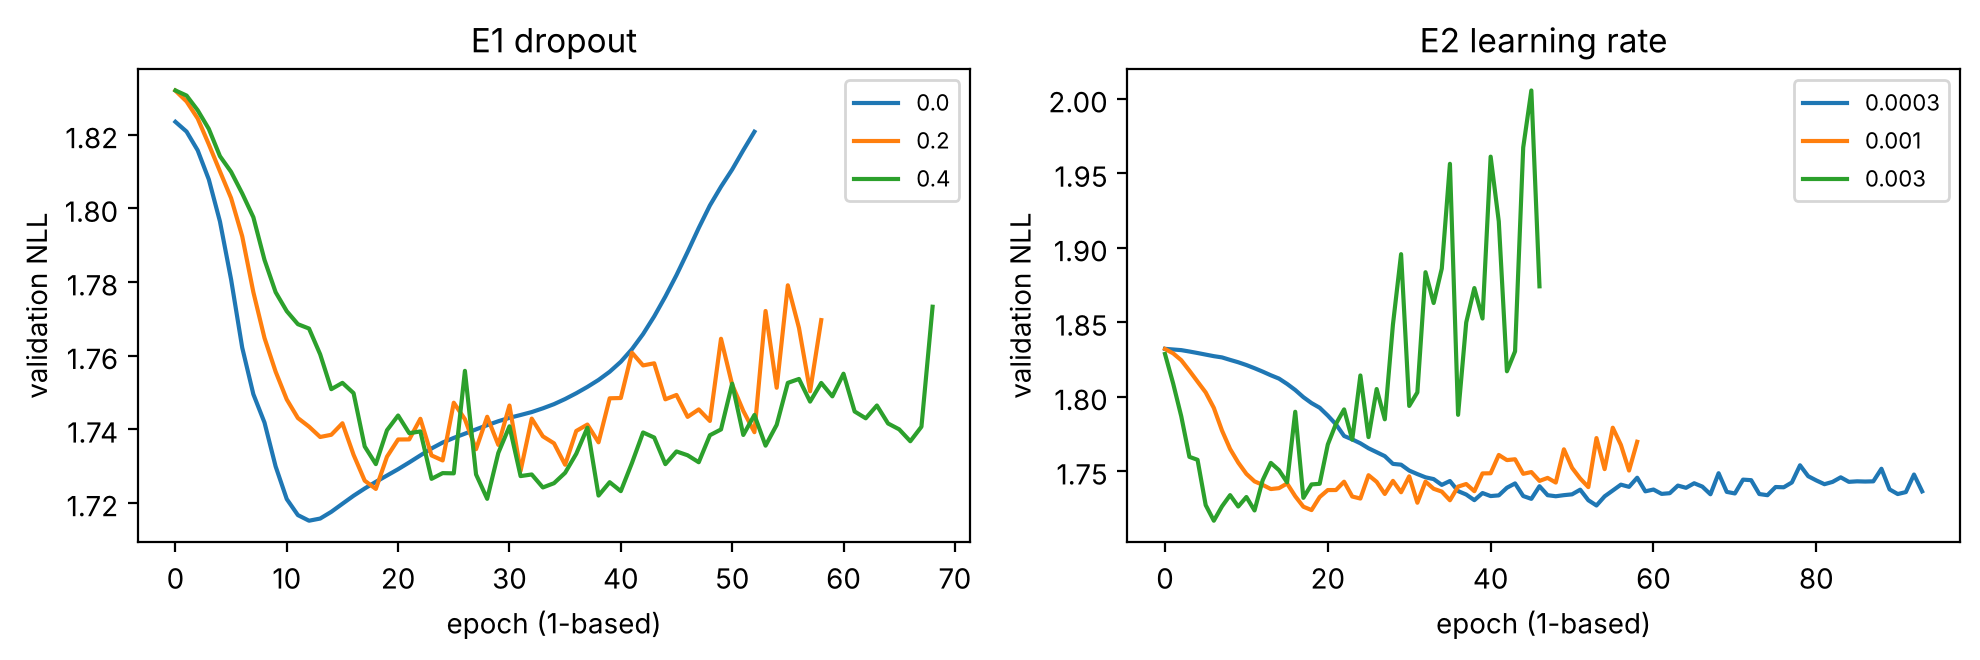

In [4]:
s2, curves = X.stage2_experiments(s1["w"])
display(s2.round(4))
X.plot_stage2(curves); plt.show()

**Reading.** Experiments 1 (dropout) and 2 (learning rate) each change one setting with all else fixed. Best-epoch validation NLL barely moves: dropout 0.4 gives 1.698 against 1.704 at 0.2 and 1.707 at 0, and learning rate 3e-3 gives 1.695 against 1.704 at 1e-3. These gains are about the size of the seed standard deviation (0.0005 to 0.011). The curves show what the table hides. With no dropout, validation NLL reaches its minimum around epoch 12 and then climbs steeply toward 1.82, while dropout 0.2 and 0.4 flatten out near 1.74 to 1.75; dropout mainly protects against overfitting after the minimum. Learning rate 3e-3 reaches its minimum fastest but becomes unstable afterwards (validation NLL spikes toward 2.0), and 3e-4 is slow (106 epochs on average). The learning-rate gain is therefore real but fragile and depends on early stopping.

### 4.1 Using the findings: combined configuration

The best single-factor settings are added one at a time, and a change is kept only if mean validation NLL improves.
The selected configuration becomes the weekly model whose forecast feeds the daily model.

In [5]:
wcfg, tune_tab, tuned_runs = X.weekly_tuned(s1["w"], s2)
display(tune_tab.round(4)); print("Selected weekly configuration:", wcfg)
json.dump(wcfg, open("results/weekly_cfg.json", "w"))
tuned = P.ensemble(tuned_runs)
tt = X._rows({"GARCH-LSTM-t baseline cfg (x3)": s1["res"]["GARCH-LSTM-t (x3)"], "GARCH-LSTM-t tuned cfg (x3)": tuned}, s1["w"]["y"], {"val": X.WVA, "test": X.WTE})
display(tt.set_index(["split", "model"]).sort_index()[["NLL", "CRPS", "MAE", "dir_acc", "cov80"]])

,step,config,val_NLL_mean,val_NLL_sd,kept
0,"baseline (lb 8, lr 1e-3, dropout 0.2)",{},1.7042,0.0082,True
1,+ lr 0.003,{'lr': 0.003},1.6945,0.0102,True
2,+ dropout 0.4,"{'lr': 0.003, 'dropout': 0.4}",1.6848,0.0127,True


Selected weekly configuration: {'lr': 0.003, 'dropout': 0.4}


NLL    CRPS     MAE  dir_acc   cov80
split model                                                                  
test  GARCH-LSTM-t baseline cfg (x3)  2.0315  1.0887  1.4592   0.6196  0.7283
      GARCH-LSTM-t tuned cfg (x3)     2.0051  1.0779  1.4509   0.6413  0.7391
val   GARCH-LSTM-t baseline cfg (x3)  1.6972  0.7232  1.0008   0.6762  0.8190
      GARCH-LSTM-t tuned cfg (x3)     1.6800  0.7169  0.9910   0.7143  0.8286

**Reading.** Adding the two changes one at a time kept both (mean single-seed validation NLL 1.704 to 1.695 to 1.685). On the test set the tuned three-seed ensemble improves NLL (2.032 to 2.005), CRPS (1.089 to 1.078), direction accuracy (0.620 to 0.641) and 80% coverage (0.728 to 0.739). Each gain is small, about one seed standard deviation, but all point the same way, so we keep the tuned configuration as the weekly input to the daily model.

In [6]:
H.save("part3", {"tuned": tuned, "wcfg": wcfg})  # hands the tuned forecast to Part 4

saved results/part3.pkl for the next part (data fingerprint b2dc33c005be)


## 5. Revisions

This section analyzes five revisions to the Stage 2 optimization experiments. Each revision has a code cell and a Markdown cell titled **Revision** (what I changed, why, and the result). None of the revisions changes the saved weekly configuration (`results/weekly_cfg.json`) or the Part 4 hand-off.

**Revision log (for the contribution table)**

| Date | What I did | Result |
|---|---|---|
| [date] | Added the revision helpers (cached single-seed runs, one-factor function) | Shared settings are trained only once |
| [date] | Revision 1: re-ran E1 and E2 with 5 seeds | [short result] |
| [date] | Revision 2: wider and finer grid for dropout and learning rate | [short result] |
| [date] | Revision 3: new experiment E3 on L2 strength | [short result] |
| [date] | Revision 4: lr × dropout interaction (2×2 from existing results, then 3×3) | [short result] |
| [date] | Revision 5: training and validation curves with best epoch marked | [short result] |
| [date] | Revision 6: learning-rate schedule and dropout 0.5 vs the selected setting (5 seeds) | [short result] |

In [7]:
# Revision helpers. Each (configuration, seed) pair is trained once and cached,
# so settings shared by several revisions are not retrained.
BASE = dict(lookback=8, dropout=0.2, l2=1e-4, lr=1e-3)   # baseline weekly configuration
_cache = {}

def run_cfg(seed, **change):
    cfg = {**BASE, **change}
    key = (seed,) + tuple(sorted(cfg.items()))
    if key not in _cache:
        r = P.run_weekly(s1["w"], head="t", seed=seed, **cfg)
        va = r["masks"][1]
        _cache[key] = {"nll": E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"],
                       "epochs": len(r["hist"]["loss"])}
    return _cache[key]

def one_factor(param, values, seeds=range(3), **fixed):
    """Change one setting, keep everything else at BASE (or `fixed`), report val NLL over seeds."""
    rows = []
    for v in values:
        res = [run_cfg(s, **fixed, **{param: v}) for s in seeds]
        nll = [x["nll"] for x in res]
        rows.append({"param": param, "value": v, **fixed,
                     "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll),
                     "epochs_mean": np.mean([x["epochs"] for x in res]),
                     **{f"seed{s}": n for s, n in zip(seeds, nll)}})
    return pd.DataFrame(rows)

In [8]:
# Revision 1: E1 and E2 with 5 seeds instead of 3
r1_drop = one_factor("dropout", [0.0, 0.2, 0.4], seeds=range(5))
r1_lr = one_factor("lr", [3e-4, 1e-3, 3e-3], seeds=range(5))
display(r1_drop.round(4)); display(r1_lr.round(4))

# Paired check: same seed, compare each setting with the baseline (dropout 0.2, lr 1e-3)
cols = [f"seed{s}" for s in range(5)]
base = r1_drop.loc[r1_drop["value"] == 0.2, cols].values[0].astype(float)
for name, tab in [("dropout", r1_drop), ("lr", r1_lr)]:
    for _, row in tab.iterrows():
        wins = int((row[cols].values.astype(float) < base).sum())
        print(f"{name} {row['value']:g}: lower val NLL than the baseline in {wins} of 5 seeds")

,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2,seed3,seed4
0,dropout,0.0,1.7130,0.0098,53.4,1.7071,1.7064,1.7059,1.7137,1.7317
1,dropout,0.2,1.7062,0.0073,65.6,1.7157,1.7004,1.6967,1.7135,1.7050
2,dropout,0.4,1.7006,0.0092,86.4,1.7130,1.6891,1.6909,1.7060,1.7038


,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2,seed3,seed4
0,lr,0.0003,1.7152,0.0068,99.2,1.7189,1.7028,1.7189,1.7133,1.7218
1,lr,0.0010,1.7062,0.0073,65.6,1.7157,1.7004,1.6967,1.7135,1.7050
2,lr,0.0030,1.6967,0.0084,51.8,1.7086,1.6845,1.6904,1.7008,1.6992


dropout 0: lower val NLL than the baseline in 1 of 5 seeds
dropout 0.2: lower val NLL than the baseline in 0 of 5 seeds
dropout 0.4: lower val NLL than the baseline in 5 of 5 seeds
lr 0.0003: lower val NLL than the baseline in 1 of 5 seeds
lr 0.001: lower val NLL than the baseline in 0 of 5 seeds
lr 0.003: lower val NLL than the baseline in 5 of 5 seeds


### Revision 1: More seeds

**What I changed.** I re-ran Experiment 1 (dropout 0, 0.2, 0.4) and Experiment 2 (learning rate 3e-4, 1e-3, 3e-3) with 5 seeds instead of 3. I also compared each setting with the baseline seed by seed.

**Why.** With 3 seeds, the gains were about the same size as the seed standard deviation. For example, dropout 0.4 was 0.0065 lower than dropout 0.2, but the seed sd was 0.0082 to 0.0109. So we could not tell if the gains were real or just random variation.

**Result.** With 5 seeds, the ranking did not change. Dropout 0.4 has the lowest mean val NLL at 1.7006, compared with 1.7062 at dropout 0.2 and 1.7130 at dropout 0. Learning rate 3e-3 has the lowest at 1.6967, compared with 1.7062 at 1e-3 and 1.7152 at 3e-4. The gaps are still small. Dropout 0.4 is 0.0056 below the baseline, which is smaller than the seed sd (0.0073 to 0.0092). Learning rate 3e-3 is 0.0095 below, about the same as its sd (0.0084).

The paired check is much clearer. Dropout 0.4 and learning rate 3e-3 each beat the baseline in 5 of 5 seeds. Dropout 0 and learning rate 3e-4 beat it in only 1 of 5. Much of the seed sd comes from the seed itself and affects all settings in the same way, so comparing seed by seed removes it. Both gains are small, but they are consistent. The first three seeds give the same values as the original run, so the results are reproducible.

In [9]:
# Revision 2: wider and finer grid (3 seeds, other settings at the baseline)
r2_drop = one_factor("dropout", [0.3, 0.4, 0.5])
r2_lr = one_factor("lr", [2e-3, 3e-3, 5e-3])
display(r2_drop.round(4)); display(r2_lr.round(4))

,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2
0,dropout,0.3,1.6991,0.0071,85.3333,1.7090,1.6926,1.6958
1,dropout,0.4,1.6977,0.0109,91.6667,1.7130,1.6891,1.6909
2,dropout,0.5,1.6978,0.0132,106.0000,1.7135,1.6812,1.6988


,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2
0,lr,0.002,1.6948,0.0126,59.0000,1.7125,1.6840,1.6878
1,lr,0.003,1.6945,0.0102,54.0000,1.7086,1.6845,1.6904
2,lr,0.005,1.6853,0.0093,50.3333,1.6979,1.6760,1.6819


### Revision 2: Wider and finer grid

**What I changed.** I tested dropout 0.3, 0.4 and 0.5, and learning rate 2e-3, 3e-3 and 5e-3. All other settings stayed at the baseline.

**Why.** In the original experiments, the best values (dropout 0.4 and learning rate 3e-3) were the largest values tested. A better value could be outside the tested range or between two tested values. Dropout 0.4 and learning rate 3e-3 are included again as a check: with the same seeds, they should give the original 1.6977 and 1.6945.

**Result.** Dropout 0.4 and learning rate 3e-3 gave the original values again (1.6977 and 1.6945), so the runs are reproducible.

For dropout, the results are flat. Dropout 0.3 gives 1.6991, 0.4 gives 1.6977, and 0.5 gives 1.6978. The largest difference is 0.0014, which is much smaller than the seed sd (0.0071 to 0.0132). The sd grows with dropout, from 0.0071 at 0.3 to 0.0132 at 0.5, and training takes longer (85 to 106 epochs). So dropout above 0.3 gives no extra gain, and 0.4 is still a reasonable choice.

For learning rate, 2e-3 (1.6948) and 3e-3 (1.6945) are almost the same. Learning rate 5e-3 is lower at 1.6853. It beats 3e-3 in all 3 seeds, its sd (0.0093) is not larger, and it stops earliest (50 epochs). The best learning rate is again at the edge of the range. Revision 4 tests whether this gain still holds when combined with dropout 0.4.

In [10]:
# Revision 3: new experiment E3, L2 strength (3 seeds, other settings at the baseline)
r3 = one_factor("l2", [0.0, 1e-4, 1e-3])
display(r3.round(4))

,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2
0,l2,0.0000,1.7041,0.0089,70.3333,1.7164,1.7004,1.6955
1,l2,0.0001,1.7042,0.0082,70.3333,1.7157,1.7004,1.6967
2,l2,0.0010,1.7050,0.0065,92.3333,1.7140,1.6989,1.7023


### Revision 3: New experiment E3 (L2 regularization)

**What I changed.** I added a third controlled experiment that tests L2 strength 0, 1e-4 (baseline) and 1e-3. All other settings stayed at the baseline.

**Why.** The weekly model has about 8,700 parameters but only about 360 training rows, so it can overfit. Experiment 1 showed that stronger dropout helped, so stronger L2 might help too. The original experiments never tested L2. The val NLL here is computed from the predictions and does not include the L2 penalty, so the three settings can be compared fairly.

**Result.** L2 has almost no effect. Mean val NLL is 1.7041 with no L2, 1.7042 at 1e-4 and 1.7050 at 1e-3. The largest difference is 0.0009, which is much smaller than the seed sd (0.0065 to 0.0089). The single-seed values for no L2 and 1e-4 are almost the same, for example 1.7164 and 1.7157 for seed 0. L2 1e-3 trains longer (92 epochs vs. 70) and has a slightly lower sd (0.0065), but it does not improve the mean. A likely reason is that dropout and the AdamW weight decay (1e-4) already regularize the weights. We keep the baseline L2 of 1e-4.

In [11]:
# Revision 4: learning rate x dropout grid (3 seeds)
lrs, drops = [1e-3, 3e-3, 5e-3], [0.2, 0.4, 0.5]
r4 = pd.concat([one_factor("dropout", drops, lr=lr) for lr in lrs], ignore_index=True)
m = r4.pivot(index="lr", columns="value", values="val_NLL_mean")
sd = r4.pivot(index="lr", columns="value", values="val_NLL_sd")
print("Mean val NLL (rows = lr, columns = dropout)")
print(m.round(4).to_string())
print("\nSeed sd of val NLL")
print(sd.round(4).to_string())
print("\nChange in val NLL from dropout 0.2 to 0.4 at each lr:", (m[0.4] - m[0.2]).round(4).to_dict())

Mean val NLL (rows = lr, columns = dropout)
value     0.2     0.4     0.5
lr                           
0.001  1.7042  1.6977  1.6978
0.003  1.6945  1.6848  1.6847
0.005  1.6853  1.6866  1.6803

Seed sd of val NLL
value     0.2     0.4     0.5
lr                           
0.001  0.0082  0.0109  0.0132
0.003  0.0102  0.0127  0.0071
0.005  0.0093  0.0138  0.0150

Change in val NLL from dropout 0.2 to 0.4 at each lr: {0.001: -0.0066, 0.003: -0.0097, 0.005: 0.0013}


### Revision 4: Interaction between learning rate and dropout

**What I changed.** I arranged the existing results as a 2×2 table of learning rate (1e-3, 3e-3) and dropout (0.2, 0.4). Then I extended it to a 3×3 grid with learning rate 5e-3 and dropout 0.5.

**Why.** Section 4.1 added the two changes one at a time in a fixed order. This assumes that the effect of dropout does not depend on the learning rate, but this was never checked.

**Result.** The 2×2 table uses numbers already in Sections 4 and 4.1.

| | dropout 0.2 | dropout 0.4 | change from dropout |
|---|---|---|---|
| lr 1e-3 | 1.7042 | 1.6977 | −0.0065 |
| lr 3e-3 | 1.6945 | 1.6848 | −0.0097 |

At lr 1e-3 and 3e-3, dropout 0.4 lowers val NLL by a similar amount. The difference is 0.0032, which is smaller than the seed sd of about 0.01. So the two gains add up roughly.

The 3×3 grid gives the following mean val NLL (seed sd in brackets).

| lr \ dropout | 0.2 | 0.4 | 0.5 |
|---|---|---|---|
| 1e-3 | 1.7042 (0.0082) | 1.6977 (0.0109) | 1.6978 (0.0132) |
| 3e-3 | 1.6945 (0.0102) | 1.6848 (0.0127) | 1.6847 (0.0071) |
| 5e-3 | 1.6853 (0.0093) | 1.6866 (0.0138) | 1.6803 (0.0150) |

At lr 1e-3 and 3e-3, dropout 0.4 and 0.5 give almost the same result (1.6977 vs. 1.6978, and 1.6848 vs. 1.6847). At lr 5e-3, the pattern is not smooth. Dropout 0.4 is slightly worse than 0.2 (1.6866 vs. 1.6853), but dropout 0.5 is the lowest in the grid at 1.6803. Because the values go up and then down, the differences at lr 5e-3 are most likely random variation, not a real interaction. The seed sd also grows with dropout at lr 5e-3, from 0.0093 at 0.2 to 0.0138 at 0.4 and 0.0150 at 0.5, so training becomes less stable.

The lowest mean is lr 5e-3 with dropout 0.5 (1.6803). It is only 0.0045 below the selected setting, lr 3e-3 with dropout 0.4 (1.6848), and this gap is much smaller than its sd of 0.0150. It is also at the corner of the grid and is the least stable setting. So we keep the original configuration. Learning rate 3e-3 with dropout 0.5 is a good alternative. It has the same mean (1.6847) and the lowest sd in the grid (0.0071).

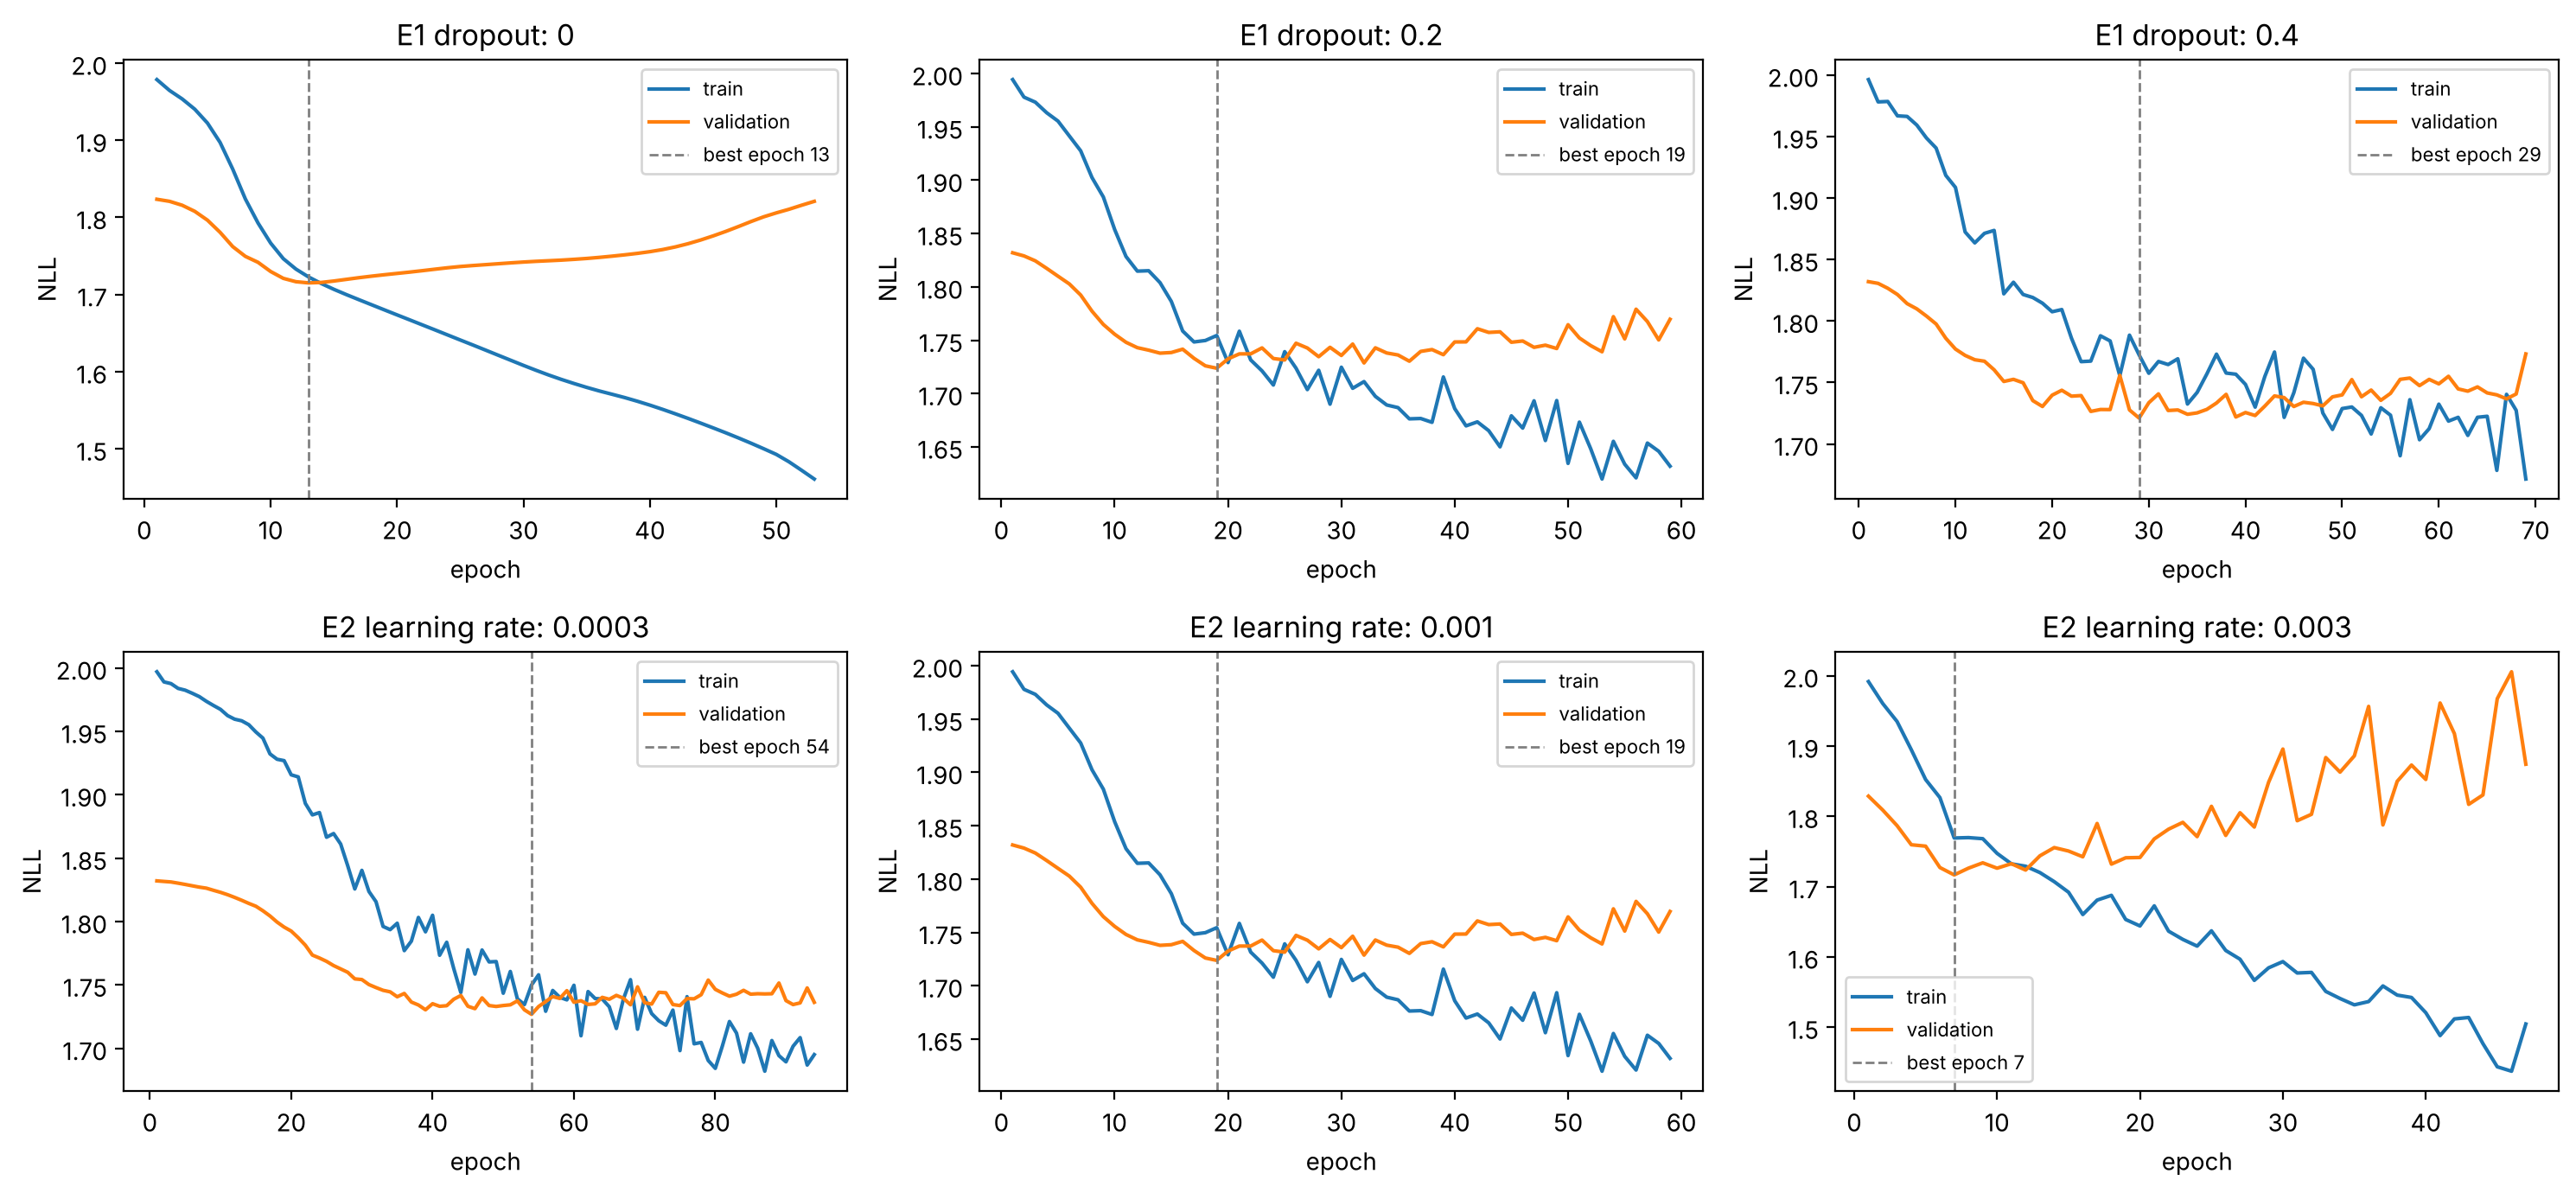

,experiment,setting,best_epoch,train_NLL_at_best,val_NLL_at_best,val_NLL_last,val_rise_after_best
0,E1 dropout,0.0000,13,1.7228,1.7151,1.8208,0.1057
1,E1 dropout,0.2000,19,1.7544,1.7238,1.7696,0.0459
2,E1 dropout,0.4000,29,1.7724,1.7211,1.7733,0.0522
3,E2 learning rate,0.0003,54,1.7499,1.7268,1.7363,0.0095
4,E2 learning rate,0.0010,19,1.7544,1.7238,1.7696,0.0459
5,E2 learning rate,0.0030,7,1.7691,1.7166,1.8741,0.1575


In [12]:
# Revision 5: training and validation NLL for every E1 and E2 setting (seed 0), best epoch marked
settings = [("E1 dropout", [0.0, 0.2, 0.4]), ("E2 learning rate", [3e-4, 1e-3, 3e-3])]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, (exp, vals) in zip(axes, settings):
    for a, v in zip(row, vals):
        h = curves[(exp, v)]
        ep = np.arange(1, len(h["loss"]) + 1)
        best = int(np.argmin(h["val_loss"])) + 1
        a.plot(ep, h["loss"], label="train")
        a.plot(ep, h["val_loss"], label="validation")
        a.axvline(best, color="gray", ls="--", lw=1, label=f"best epoch {best}")
        a.set_title(f"{exp}: {v:g}"); a.set_xlabel("epoch"); a.set_ylabel("NLL"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for (exp, v), h in curves.items():
    i = int(np.argmin(h["val_loss"]))
    rows.append({"experiment": exp, "setting": v, "best_epoch": i + 1,
                 "train_NLL_at_best": h["loss"][i], "val_NLL_at_best": h["val_loss"][i],
                 "val_NLL_last": h["val_loss"][-1],
                 "val_rise_after_best": h["val_loss"][-1] - h["val_loss"][i]})
display(pd.DataFrame(rows).round(4))

### Revision 5: Training and validation curves

**What I changed.** I plotted training and validation NLL together for every setting in Experiments 1 and 2 and marked the best epoch. I also added a table with the NLL at the best epoch and how much validation NLL rose after it.

**Why.** The original figure showed only validation NLL. Without the training curve, we could not see whether validation NLL rose while training NLL kept falling, which is the sign of overfitting.

**Result.** Without dropout, the curves show clear overfitting. Training NLL keeps falling from about 1.98 to 1.46. Validation NLL reaches its minimum of 1.7151 at epoch 13 and then rises to 1.8208, an increase of 0.1057. With dropout 0.2 and 0.4, validation NLL stays roughly flat after the best epoch. It rises by only 0.0459 and 0.0522, about half as much. Dropout also moves the best epoch later, to epoch 19 and 29.

For learning rate, 3e-4 is slow but very stable. Its best epoch is 54, and validation NLL rises by only 0.0095 afterwards. Learning rate 3e-3 reaches its best epoch fastest, at epoch 7. After that, validation NLL rises with large spikes up to about 2.0, the largest rise at 0.1575. So the gain from lr 3e-3 depends on early stopping restoring the weights from epoch 7.

In all settings, training NLL starts higher than validation NLL (about 1.98 vs. 1.83). This also happens without dropout, so it likely comes from the different volatility in the two periods, not only from dropout.

sanity check (seed 0, lr 3e-3, dropout 0.4): new function 1.7013 vs revision helper 1.7013


                                       val_NLL_mean  val_NLL_sd  best_epoch_mean  val_rise_after_best_mean  seeds_better_than_A   seed0   seed1   seed2   seed3   seed4
config                                                                                                                                                                 
A: lr 3e-3, dropout 0.4 (selected)           1.6856      0.0099             20.8                    0.2294                    0  1.7013  1.6702  1.6830  1.6868  1.6869
B: lr 3e-3, dropout 0.5                      1.6864      0.0060             21.2                    0.1580                    1  1.6942  1.6769  1.6831  1.6906  1.6873
C: lr 3e-3, dropout 0.4 + LR schedule        1.6856      0.0099             20.8                    0.0787                    0  1.7013  1.6702  1.6830  1.6868  1.6869
D: lr 3e-3, dropout 0.5 + LR schedule        1.6864      0.0060             21.2                    0.0600                    1  1.6942  1.6769  1.6831  1.6906 

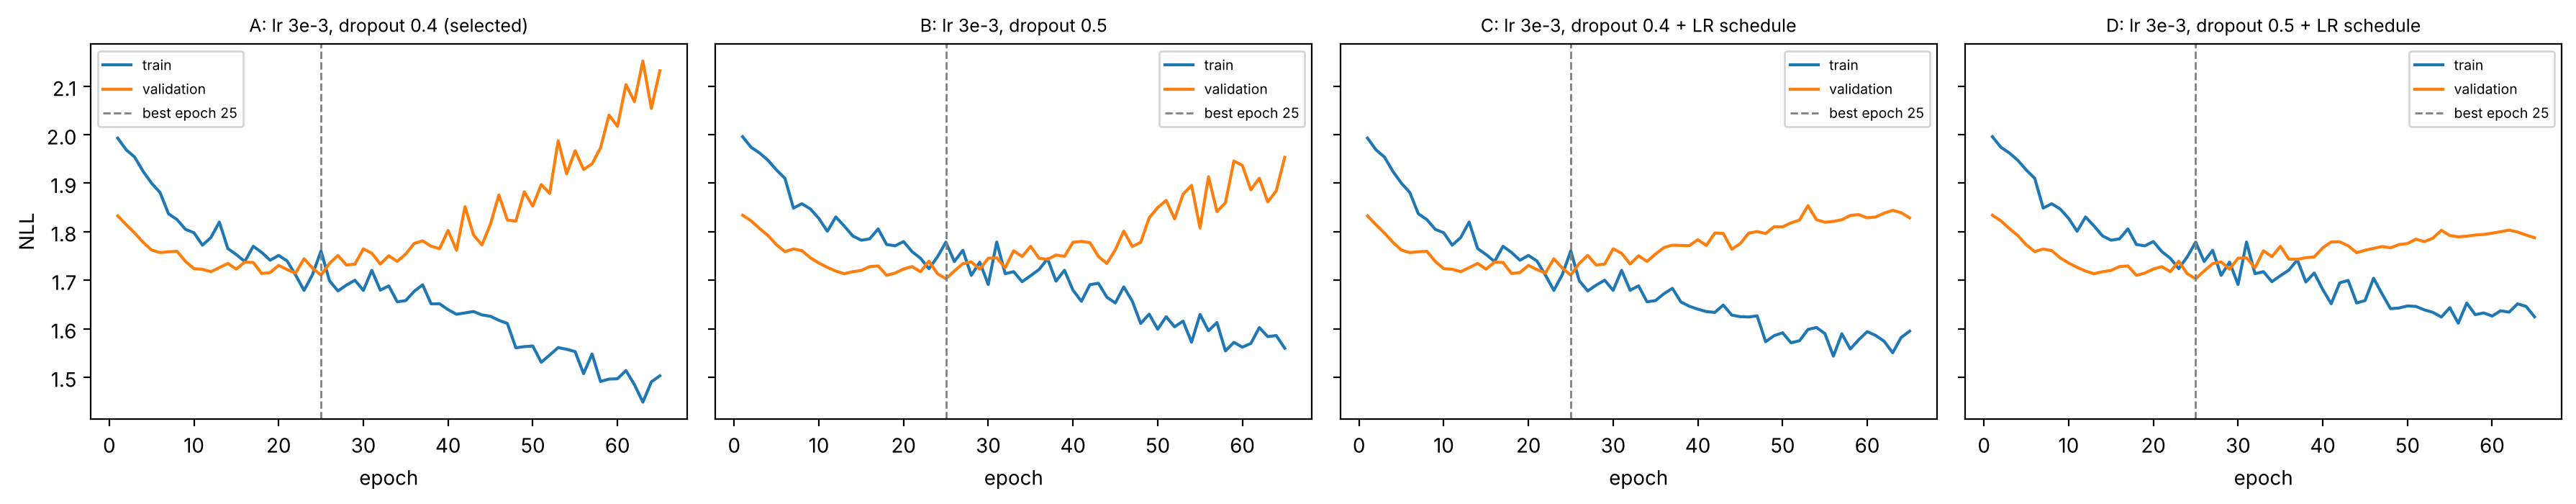

In [13]:
# Revision 6: lower validation NLL without overfitting after the best epoch.
# Same model, data, splits and early stopping as P.run_weekly, plus an optional learning-rate schedule:
# ReduceLROnPlateau halves the learning rate when validation NLL stops improving for 10 epochs.
from tensorflow import keras

def run_weekly_v2(seed=0, lr=3e-3, dropout=0.4, l2=1e-4, lookback=8, units=(32, 16),
                  schedule=False, factor=0.5, lr_patience=10, min_lr=1e-4, patience=40, epochs=400):
    w = s1["w"]; feats = D.WEEKLY_FEATS
    X, y, idx = D.sequences(w, feats, lookback)
    tr, va, te = P.split_masks(idx, P.W_SPLIT, P.W_SPLIT.get("train_start"))
    tr &= ~np.isnan(y); va &= ~np.isnan(y)
    sc = M.Scaler(keep_last_raw=True).fit(X[tr])
    m = M.build_lstm(X.shape[1], X.shape[2], head="t", seed=seed, units=units, dropout=dropout, l2=l2)
    m.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4, clipnorm=1.0), loss=M.nll_t)
    cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]
    if schedule:
        cb.append(keras.callbacks.ReduceLROnPlateau("val_loss", factor=factor, patience=lr_patience, min_lr=min_lr))
    h = m.fit(sc(X[tr]), y[tr][:, None] * 100, validation_data=(sc(X[va]), y[va][:, None] * 100),
              epochs=epochs, batch_size=32, callbacks=cb, verbose=0, shuffle=True).history
    d = M.predict_dist(m, sc(X), "t"); d.index = idx
    nll = E.dist_metrics(y[va] * 100, d[va])["NLL"]
    best = int(np.argmin(h["val_loss"]))
    return {"val_NLL": nll, "best_epoch": best + 1, "val_rise_after_best": h["val_loss"][-1] - h["val_loss"][best], "hist": h}

# Sanity check: without a schedule, this function must reproduce the cached result from the revision helpers
chk = run_weekly_v2(seed=0, lr=3e-3, dropout=0.4)["val_NLL"]
ref = run_cfg(0, lr=3e-3, dropout=0.4)["nll"]
print(f"sanity check (seed 0, lr 3e-3, dropout 0.4): new function {chk:.4f} vs revision helper {ref:.4f}")

R6 = {"A: lr 3e-3, dropout 0.4 (selected)":       dict(lr=3e-3, dropout=0.4),
      "B: lr 3e-3, dropout 0.5":                   dict(lr=3e-3, dropout=0.5),
      "C: lr 3e-3, dropout 0.4 + LR schedule":     dict(lr=3e-3, dropout=0.4, schedule=True),
      "D: lr 3e-3, dropout 0.5 + LR schedule":     dict(lr=3e-3, dropout=0.5, schedule=True)}
SEEDS6 = range(5)
r6_runs = {name: [run_weekly_v2(seed=s, **cfg) for s in SEEDS6] for name, cfg in R6.items()}

base = np.array([r["val_NLL"] for r in r6_runs["A: lr 3e-3, dropout 0.4 (selected)"]])
rows = []
for name, runs in r6_runs.items():
    nll = np.array([r["val_NLL"] for r in runs])
    rows.append({"config": name, "val_NLL_mean": nll.mean(), "val_NLL_sd": nll.std(),
                 "best_epoch_mean": np.mean([r["best_epoch"] for r in runs]),
                 "val_rise_after_best_mean": np.mean([r["val_rise_after_best"] for r in runs]),
                 "seeds_better_than_A": int((nll < base).sum()),
                 **{f"seed{s}": v for s, v in zip(SEEDS6, nll)}})
r6 = pd.DataFrame(rows).set_index("config")
print(r6.round(4).to_string())

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for a, (name, runs) in zip(axes, r6_runs.items()):
    h = runs[0]["hist"]; ep = np.arange(1, len(h["loss"]) + 1); b = int(np.argmin(h["val_loss"])) + 1
    a.plot(ep, h["loss"], label="train"); a.plot(ep, h["val_loss"], label="validation")
    a.axvline(b, color="gray", ls="--", lw=1, label=f"best epoch {b}")
    a.set_title(name.split(":")[0] + ":" + name.split(":")[1], fontsize=9); a.set_xlabel("epoch"); a.legend(fontsize=7)
axes[0].set_ylabel("NLL"); plt.tight_layout(); plt.show()


### Revision 6: Lower validation NLL without overfitting after the best epoch

**What I changed.** I compared four settings of the weekly GARCH-LSTM-t with 5 seeds. A is the selected setting (lr 3e-3, dropout 0.4). B uses dropout 0.5, which had the same mean and the lowest seed sd in Revision 4. C and D add a learning-rate schedule (ReduceLROnPlateau) to A and B. The schedule halves the learning rate when validation NLL has not improved for 10 epochs, down to 1e-4. Everything else is unchanged: same data, splits, early stopping (patience 40, best weights restored) and seeds. A sanity check confirms that the new training function reproduces the earlier result when no schedule is used.

**Why.** Revision 5 showed that lr 3e-3 reaches its best epoch fastest (epoch 7) but then overfits the most (validation NLL rose by 0.1575 after the best epoch). Its low validation NLL depends on early stopping catching the right epoch. A learning-rate schedule keeps the large steps at the start and takes smaller steps once progress stops, so validation NLL should stay near its minimum instead of rising. The selection rule was set before running: choose the lowest mean validation NLL; if two settings are within one seed sd of each other, prefer the one with the smaller rise after the best epoch.

**Result.** The sanity check passed. Without a schedule, the new function gives 1.7013 for seed 0, the same as the revision helper.

The learning-rate schedule did not change the final model. C has exactly the same validation NLL as A for every seed (mean 1.6856, sd 0.0099), and D is the same as B (mean 1.6864, sd 0.0060). The best epochs are also the same. The schedule lowers the learning rate only after validation NLL has not improved for 10 epochs. In every run this happened after the best epoch, and the lower learning rate never found a lower validation NLL. Early stopping then restored the same best-epoch weights.

The schedule did change what happens after the best epoch. Validation NLL rose by 0.2295 on average without the schedule (A) and by 0.0787 with it (C), about one third as much. With dropout 0.5, the rise fell from 0.1580 (B) to 0.0600 (D). So the schedule removes most of the overfitting after the minimum. Because early stopping already discards those epochs, the reported model does not change.

Dropout 0.5 and dropout 0.4 give almost the same validation NLL. B is 0.0008 higher than A, which is much smaller than the seed sd, and it beats A in only 1 of 5 seeds. B is more stable across seeds (sd 0.0060 vs. 0.0099) and overfits less after the best epoch (0.1580 vs. 0.2295).

Under the rule set before running, all four settings are within one seed sd, so the setting with the smallest rise wins. That is D (rise 0.0600). D gives the same final model as B, so in practice the choice is dropout 0.5 instead of 0.4. We therefore change the weekly configuration to lr 3e-3 with dropout 0.5 and re-run Part 4 with it. 